# Poisson surrogates for alignment-based conformance checking on **exact** models

## 0 · Setup

In [1]:
import os, sys, time, random, warnings, gc, json, platform, copy, itertools
import numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             mean_absolute_error, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score,
                             confusion_matrix)
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from collections import deque, Counter
from lxml import etree
from IPython.display import Image, display
import pm4py
from pm4py.util import constants as pm_const
try: pm_const.SHOW_PROGRESS_BAR = False
except Exception: pass
from pm4py.algo.conformance.alignments.petri_net import algorithm as alignments
warnings.filterwarnings("ignore")

SEED = 42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else platform.processor())

# ── figure identity (validated categorical order — never recycled) ────────────
CAT   = ["#2a78d6", "#008300", "#e87ba4", "#eda100", "#1baf7a", "#eb6834"]
ORACLE = "#52514e"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURF = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list(
    "b", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID, "axes.grid": True,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "font.family": "sans-serif", "font.size": 10, "figure.dpi": 110,
    "legend.frameon": False, "axes.titlesize": 11, "axes.titlecolor": INK})

FIG = "figures_poisson"; os.makedirs(FIG, exist_ok=True)
def save_fig(fig, name):
    fig.savefig(f"{FIG}/{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"{FIG}/{name}.pdf", bbox_inches="tight")
def legend_on_data(ax, **kw):
    return ax.legend(frameon=True, framealpha=.88, edgecolor="none",
                     facecolor=SURF, fontsize=8.5, **kw)
def label_panels(fig):
    "Label multi-panel figures (a), (b), (c) so the text can cite one panel."
    axs = fig.axes
    if len(axs) < 2: return
    for i, a in enumerate(axs):
        a.text(-0.06, 1.11, f"({chr(97+i)})", transform=a.transAxes, fontsize=11,
               fontweight="bold", color=INK, va="top", ha="left")

def fmt_speedup(r):
    if r >= 10: return f"{r:.0f}x faster"
    if r >= 1:  return f"{r:.1f}x faster"
    return f"{1/r:.1f}x slower"

# ── data ─────────────────────────────────────────────────────────────────────
PDC_DIR   = "data_exact_models/pdc2021"
MODEL_DIR, TRAIN_DIR, GT_DIR = f"{PDC_DIR}/Models", f"{PDC_DIR}/TrainingLogs", f"{PDC_DIR}/GroundTruthLogs"
assert os.path.isdir(MODEL_DIR), f"PDC 2021 not found under {PDC_DIR}"

TYPES  = ["skip", "insert", "rework"]
TCOL   = {"skip": CAT[0], "insert": CAT[1], "rework": CAT[2]}
ARCHS  = ["mlp", "gru", "lstm"]
LABEL  = {"mlp": "MLP", "gru": "GRU", "lstm": "LSTM"}
MCOL   = {"mlp": CAT[0], "gru": CAT[1], "lstm": CAT[2]}

# configurations: nu -> long-term deps -> loops/OR/optional -> everything
CFGS        = ["000000", "100000", "011010", "121111"]
# Readable names: the six-digit PDC codes are unreadable in figures and captions.
CFG_NAME    = {"000000": "Model 1", "100000": "Model 2",
               "011010": "Model 3", "121111": "Model 4"}
def mname(c): return CFG_NAME.get(c, f"pdc_{c}")
GT_CFGS     = ["000000", "100000", "010000", "020000", "001000", "000100",
               "000010", "000001", "011010", "101010", "110101", "121111"]
SEARCH_CFGS = ["000000", "121111"]      # architecture search: easiest + hardest
STREAM_CFGS = ["000000", "121111"]

N_CLEAN   = 1000     # clean traces available per configuration
PASSES    = 6        # anti-log passes over each clean split (Def. 7.1 keeps 60% intact)
MAGNITUDE = 3        # operations per deviant trace, ALL of the same type (1 = Def. 7.1)
SEV_GRID  = [1, 2, 3, "prop"]   # severity sweep reported in §4b
MAXLEN    = 45
T_TRACE, T_LOG = 5, 60
FIT_TOL   = 0.999    # A*: a trace fits when its alignment fitness exceeds this
TAU_DOC   = 0.70     # documented default decision threshold (eq. 16)
ALPHA     = 0.1      # calibration weight (eq. 18)
EPOCHS, SEARCH_EPOCHS = 30, 15
N_LAT     = 200
BATCHES   = [1, 8, 32, 128, 512]
STREAM_N, WARMUP, PREQ_W = 1600, 250, 150

# Anti-log procedure — Def. 7.1
PI = {"none": 0.60, "skip": 0.15, "insert": 0.15, "rework": 0.10}

if os.environ.get("SMOKE") == "1":
    CFGS = ["000000"]; GT_CFGS = ["000000", "121111"]
    SEARCH_CFGS = ["000000"]; STREAM_CFGS = ["000000"]
    N_CLEAN, PASSES = 150, 2
    EPOCHS, SEARCH_EPOCHS = 3, 2
    SEV_GRID = [1, 3]
    N_LAT = 30; BATCHES = [1, 32]
    STREAM_N, WARMUP, PREQ_W = 300, 60, 50
    print(">>> SMOKE MODE — tiny caps, results are not publishable")

print("train/eval configs:", CFGS, "| search:", SEARCH_CFGS, "| stream:", STREAM_CFGS)

Device: cuda | NVIDIA GeForce RTX 3070 Ti Laptop GPU
train/eval configs: ['000000', '100000', '011010', '121111'] | search: ['000000', '121111'] | stream: ['000000', '121111']


## 1 · The exact models and their logs

In [2]:
def _ln(t): return t.rsplit('}', 1)[-1]

def parse_xes_fast(path, max_traces=None):
    out = []
    ctx = etree.iterparse(path, events=("end",), recover=True, huge_tree=True)
    for _, elem in ctx:
        if _ln(elem.tag) != "trace": continue
        ispos = None; acts = []
        for ch in elem:
            ln = _ln(ch.tag)
            if ln == "boolean" and ch.get("key") == "pdc:isPos":
                ispos = (str(ch.get("value", "")).lower() == "true")
            elif ln == "event":
                for g in ch:
                    if _ln(g.tag) == "string" and g.get("key") == "concept:name":
                        acts.append(g.get("value")); break
        if acts: out.append((acts, ispos))
        elem.clear()
        while elem.getprevious() is not None: del elem.getparent()[0]
        if max_traces and len(out) >= max_traces: break
    del ctx; gc.collect(); return out

def load_model(cfg): return pm4py.read_pnml(f"{MODEL_DIR}/pdc2021_{cfg}.pnml")
def load_clean(cfg, n=None):
    return [t[0] for t in parse_xes_fast(f"{TRAIN_DIR}/pdc2021_{cfg}0.xes", max_traces=n)]
def load_gt(cfg):
    "[(activities, deviating 0/1)] — 1 = does NOT fit the exact model."
    return [(t[0], 0 if t[1] else 1) for t in parse_xes_fast(f"{GT_DIR}/pdc2021_{cfg}.xes")]

FEAT = ["long-term deps", "loops", "OR", "silent routing", "optional", "duplicate"]
rows = []
for cfg in GT_CFGS:
    net, im, fm = load_model(cfg)
    tr = load_clean(cfg, 300)
    v = [int(c) for c in cfg]
    rows.append({"config": cfg, **{FEAT[i]: v[i] for i in range(6)},
                 "places": len(net.places), "transitions": len(net.transitions),
                 "silent": sum(1 for t in net.transitions if t.label is None),
                 "activities": len({t.label for t in net.transitions if t.label}),
                 "median |trace|": int(np.median([len(t) for t in tr])),
                 "max |trace|": int(max(len(t) for t in tr))})
df_models = pd.DataFrame(rows).set_index("config")
print(f"{len(df_models)} exact models loaded")
df_models

12 exact models loaded


,long-term deps,loops,OR,silent routing,optional,duplicate,places,transitions,silent,activities,median |trace|,max |trace|
config,,,,,,,,,,,,
000000,0,0,0,0,0,0,44,51,1,50,15,33
100000,1,0,0,0,0,0,47,53,3,50,15,32
010000,0,1,0,0,0,0,47,61,1,60,16,123
020000,0,2,0,0,0,0,47,64,1,63,17,185
001000,0,0,1,0,0,0,44,53,3,50,15,31
000100,0,0,0,1,0,0,44,51,10,41,12,28
000010,0,0,0,0,1,0,44,57,7,50,6,32
000001,0,0,0,0,0,1,44,51,1,43,15,33
011010,0,1,1,0,1,0,47,72,12,60,6,154


### 1.1 · Views on the exact models

pdc2021_000000  —  44p / 51t, 1 silent, 50 activities


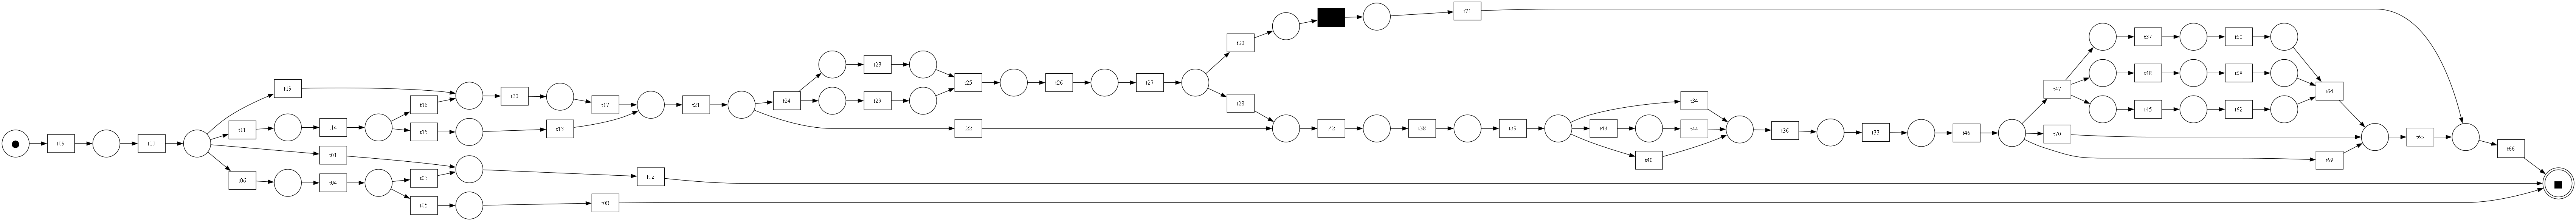

pdc2021_100000  —  47p / 53t, 3 silent, 50 activities


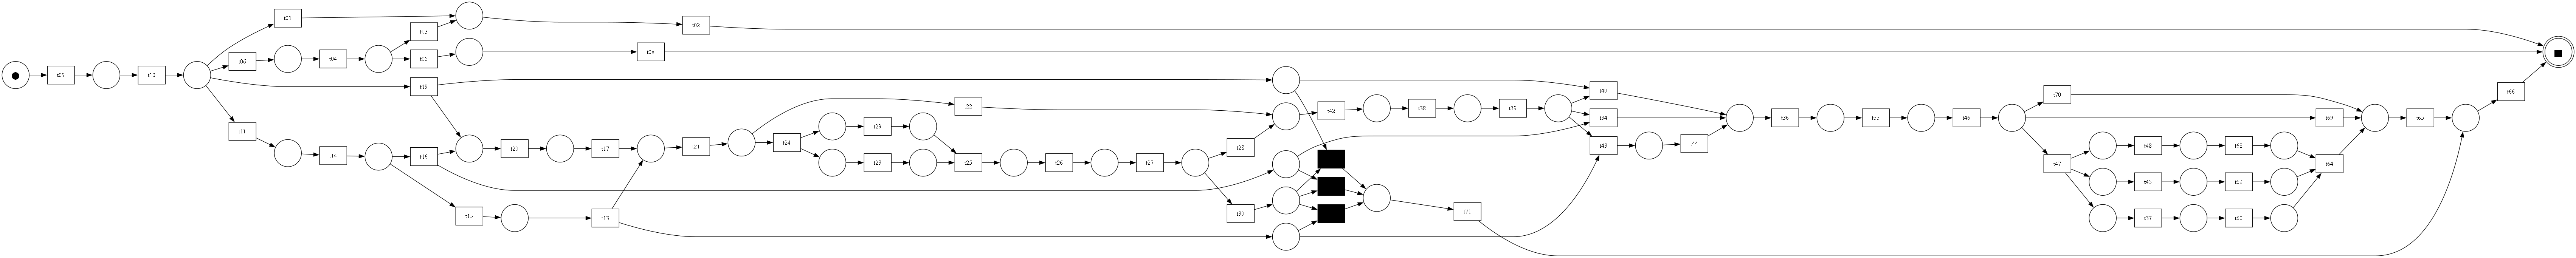

pdc2021_011010  —  47p / 72t, 12 silent, 60 activities


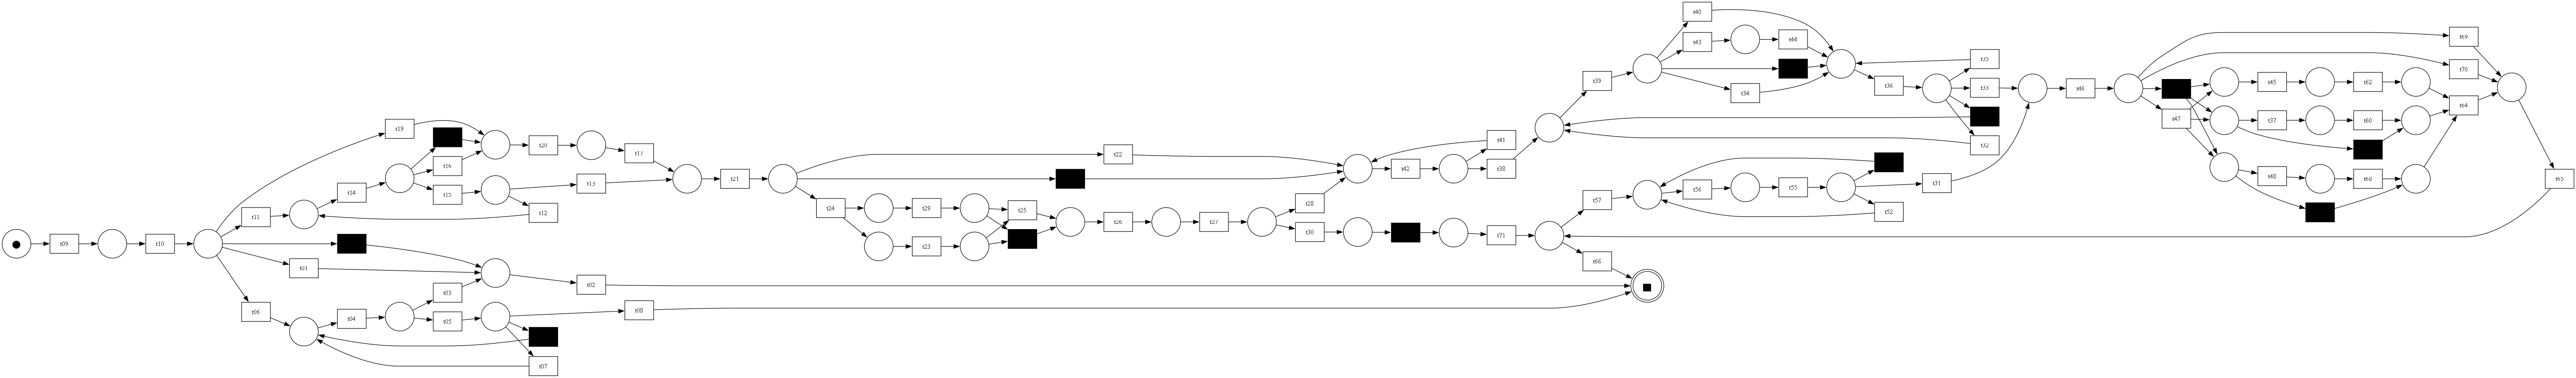

pdc2021_121111  —  50p / 78t, 30 silent, 39 activities


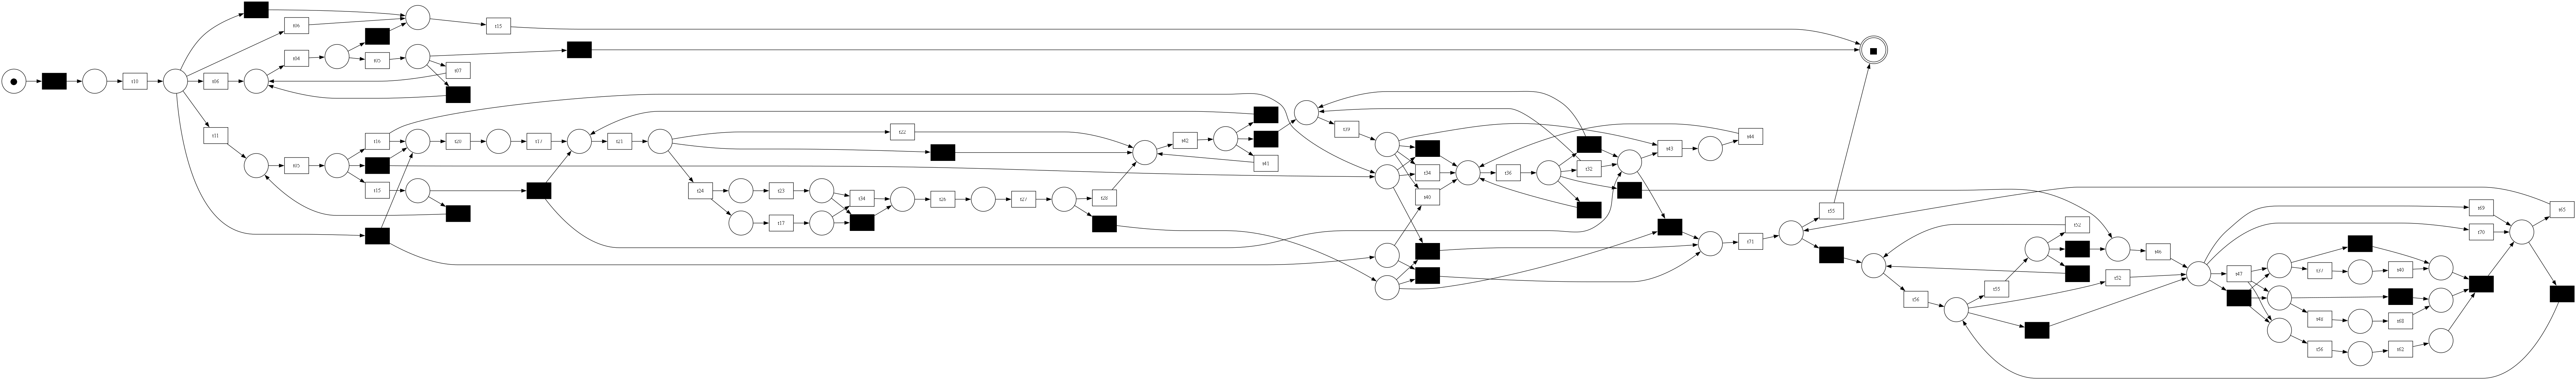

In [3]:
for cfg in CFGS:
    net, im, fm = load_model(cfg)
    f = f"{FIG}/model_{cfg}.png"
    try:
        pm4py.save_vis_petri_net(net, im, fm, f)
        r = df_models.loc[cfg]
        print(f"pdc2021_{cfg}  —  {r.places}p / {r.transitions}t, {r.silent} silent, "
              f"{r.activities} activities")
        display(Image(f))
    except Exception as e:
        print(f"pdc2021_{cfg} — rendering unavailable ({type(e).__name__})")

## 2 · The A\* oracle and its accuracy

In [4]:
V = alignments.Variants.VERSION_STATE_EQUATION_A_STAR
PARAM = V.value.Parameters
APARAMS = {PARAM.PARAM_MAX_ALIGN_TIME_TRACE: T_TRACE, PARAM.PARAM_MAX_ALIGN_TIME: T_LOG}
BASE_TS = pd.Timestamp("2020-01-01", tz="UTC")

def traces_to_log(trs):
    rows = [{"case:concept:name": f"c{i:06d}", "concept:name": a,
             "time:timestamp": BASE_TS + pd.Timedelta(seconds=j)}
            for i, tr in enumerate(trs) for j, a in enumerate(tr)]
    return pm4py.convert_to_event_log(pm4py.format_dataframe(pd.DataFrame(rows)))

def astar_labels(trs, net, im, fm):
    "(index_ok, y[1=deviating], fitness, ms/trace)"
    t0 = time.perf_counter()
    res = alignments.apply_log(traces_to_log(trs), net, im, fm, variant=V, parameters=APARAMS)
    ms = (time.perf_counter() - t0) * 1000 / max(1, len(trs))
    ok = [i for i, a in enumerate(res) if a is not None and a.get("fitness") is not None]
    y = np.array([0 if res[i]["fitness"] > FIT_TOL else 1 for i in ok], dtype=int)
    f = np.array([res[i]["fitness"] for i in ok], dtype=float)
    return ok, y, f, ms

def astar_per_trace(trs, net, im, fm, warm=3):
    "Per-trace wall clock of the alignment search only (log conversion excluded)."
    log = traces_to_log(trs); rows = []
    for i in range(min(warm, len(log))):
        try: alignments.apply(log[i], net, im, fm, variant=V,
                              parameters={PARAM.PARAM_MAX_ALIGN_TIME_TRACE: T_TRACE})
        except Exception: pass
    for tr in log:
        t0 = time.perf_counter()
        try:
            a = alignments.apply(tr, net, im, fm, variant=V,
                                 parameters={PARAM.PARAM_MAX_ALIGN_TIME_TRACE: T_TRACE})
            ms = (time.perf_counter() - t0) * 1000
            fit = a["fitness"] if a is not None and a.get("fitness") is not None else np.nan
        except Exception:
            ms, fit = (time.perf_counter() - t0) * 1000, np.nan
        rows.append({"ms": ms, "fitness": fit, "length": len(tr)})
    return pd.DataFrame(rows)

orows = []; GT_CACHE = {}
for cfg in GT_CFGS:
    net, im, fm = load_model(cfg)
    _, _, f_clean, ms_clean = astar_labels(load_clean(cfg, 120), net, im, fm)
    gt = load_gt(cfg); GT_CACHE[cfg] = gt
    trs = [t[0] for t in gt]; y_true = np.array([t[1] for t in gt])
    ok, y_pred, _, ms_gt = astar_labels(trs, net, im, fm)
    yt = y_true[ok]
    orows.append({"config": cfg,
                  "fitness (clean log)": round(float(np.mean(f_clean)), 6),
                  "accuracy": round(accuracy_score(yt, y_pred), 4),
                  "precision": round(precision_score(yt, y_pred, zero_division=0), 4),
                  "recall": round(recall_score(yt, y_pred, zero_division=0), 4),
                  "F1": round(f1_score(yt, y_pred, zero_division=0), 4),
                  "aligned %": round(100 * len(ok) / len(gt), 1),
                  "ms/trace": round(ms_gt, 2)})
    print(f"  pdc2021_{cfg}: clean fitness={np.mean(f_clean):.6f} | "
          f"GT accuracy={orows[-1]['accuracy']:.4f} | {ms_gt:.1f} ms/trace")
df_oracle = pd.DataFrame(orows).set_index("config")
df_oracle.to_csv("poisson_oracle_accuracy.csv")
print(f"\nA* accuracy on the real ground truth: {df_oracle.accuracy.mean():.4f} "
      f"(mean over {len(df_oracle)} exact models)")
df_oracle

  pdc2021_000000: clean fitness=1.000000 | GT accuracy=1.0000 | 8.9 ms/trace


  pdc2021_100000: clean fitness=1.000000 | GT accuracy=1.0000 | 11.9 ms/trace


  pdc2021_010000: clean fitness=1.000000 | GT accuracy=1.0000 | 92.6 ms/trace


  pdc2021_020000: clean fitness=1.000000 | GT accuracy=1.0000 | 45.8 ms/trace


  pdc2021_001000: clean fitness=1.000000 | GT accuracy=1.0000 | 11.1 ms/trace


  pdc2021_000100: clean fitness=1.000000 | GT accuracy=1.0000 | 10.3 ms/trace


... (3 outputs left out)

  pdc2021_101010: clean fitness=1.000000 | GT accuracy=1.0000 | 12.4 ms/trace


  pdc2021_110101: clean fitness=1.000000 | GT accuracy=1.0000 | 58.5 ms/trace


  pdc2021_121111: clean fitness=1.000000 | GT accuracy=1.0000 | 83.7 ms/trace

A* accuracy on the real ground truth: 1.0000 (mean over 12 exact models)


,fitness (clean log),accuracy,precision,recall,F1,aligned %,ms/trace
config,,,,,,,
000000,1.0,1.0,1.0,1.0,1.0,100.0,8.90
100000,1.0,1.0,1.0,1.0,1.0,100.0,11.87
010000,1.0,1.0,1.0,1.0,1.0,99.6,92.59
020000,1.0,1.0,1.0,1.0,1.0,100.0,45.81
001000,1.0,1.0,1.0,1.0,1.0,100.0,11.13
000100,1.0,1.0,1.0,1.0,1.0,100.0,10.30
000010,1.0,1.0,1.0,1.0,1.0,100.0,10.85
000001,1.0,1.0,1.0,1.0,1.0,100.0,15.72
011010,1.0,1.0,1.0,1.0,1.0,99.6,129.65


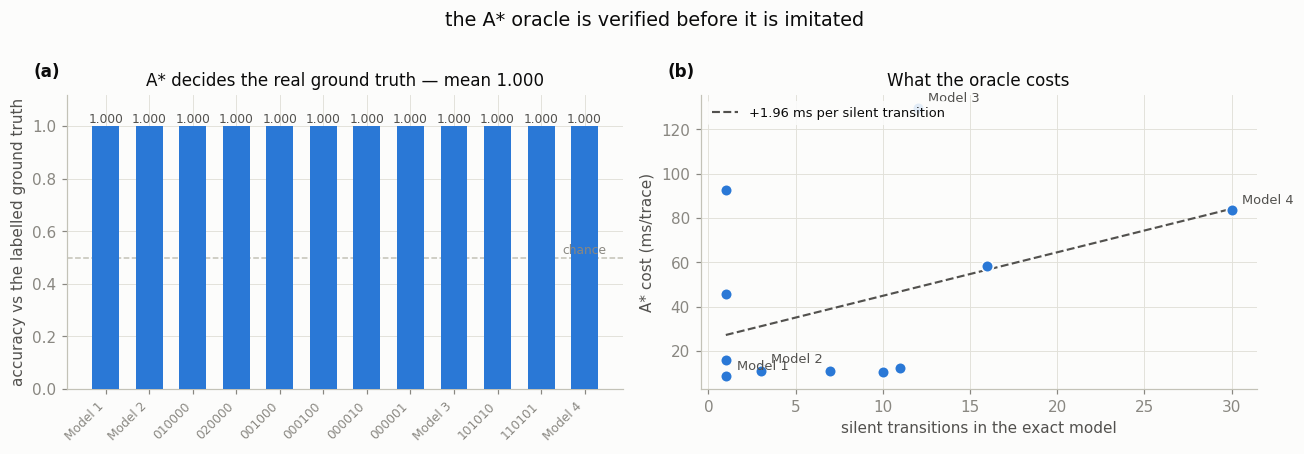

In [5]:
# Fig 1 — the oracle: accuracy on the real ground truth, and what it costs
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
x = np.arange(len(df_oracle))
ax.bar(x, df_oracle["accuracy"], .62, color=CAT[0], zorder=3)
for i, v in enumerate(df_oracle["accuracy"]):
    ax.text(i, v + .012, f"{v:.3f}", ha="center", fontsize=8, color=INK2)
ax.axhline(0.5, color=AXIS, lw=1, ls="--", zorder=2)
ax.text(len(df_oracle) - .5, .515, "chance", fontsize=8, color=MUTED, ha="right")
ax.set_xticks(x, [CFG_NAME.get(c, c) for c in df_oracle.index], rotation=45, ha="right", fontsize=8)
ax.set_ylim(0, 1.12); ax.set_ylabel("accuracy vs the labelled ground truth")
ax.set_title(f"A* decides the real ground truth — mean {df_oracle.accuracy.mean():.3f}")

ax = axes[1]
sub = df_models.loc[df_oracle.index]
ax.scatter(sub["silent"], df_oracle["ms/trace"], s=60, color=CAT[0],
           edgecolor=SURF, linewidth=1.2, zorder=3)
for c in df_oracle.index:                      # n'annoter que les modeles etudies
    if c not in CFG_NAME: continue
    ax.annotate(CFG_NAME[c], (sub.loc[c, "silent"], df_oracle.loc[c, "ms/trace"]),
                textcoords="offset points", xytext=(7, 4), fontsize=8.5, color=INK2)
if sub["silent"].nunique() > 2:
    z = np.polyfit(sub["silent"], df_oracle["ms/trace"], 1)
    xs = np.linspace(sub["silent"].min(), sub["silent"].max(), 40)
    ax.plot(xs, np.polyval(z, xs), color=INK2, lw=1.4, ls="--", zorder=2,
            label=f"+{z[0]:.2f} ms per silent transition")
    legend_on_data(ax, loc="upper left")
ax.set_xlabel("silent transitions in the exact model")
ax.set_ylabel("A* cost (ms/trace)"); ax.set_title("What the oracle costs")
fig.suptitle("the A* oracle is verified before it is imitated",
             fontsize=12.5, color=INK, y=1.02)
plt.tight_layout(); label_panels(fig); save_fig(fig, "fig1_oracle"); plt.show()

## 3 · Anti-logs — injection per Def. 7.1
### Magnitude is a separate knob from type

In [6]:
def antilog(trace, rng, magnitude=1):
    # Anti-log of one trace. Type mix and the 60/40 clean/deviant split follow Def. 7.1.
    # `magnitude` is the number of operations applied, ALL OF THE SAME TYPE, so a trace
    # never mixes types (this keeps the per-type problem well posed) while the strength
    # of the deviation stays a free, reportable parameter. magnitude=1 is Def. 7.1
    # exactly; "prop" applies 20 percent of the trace length.
    t = list(trace); c = [0, 0, 0]; u = rng.random()
    if u < PI["none"] or len(t) < 3:
        return t, c, "none"
    if   u < PI["none"] + PI["skip"]:                 kind, k = "skip", 0
    elif u < PI["none"] + PI["skip"] + PI["insert"]:  kind, k = "insert", 1
    else:                                             kind, k = "rework", 2
    m = max(2, int(round(0.20 * len(t)))) if magnitude == "prop" else int(magnitude)
    for _ in range(m):
        if kind == "skip":
            if len(t) > 2: t.pop(rng.randrange(len(t))); c[0] += 1
        elif kind == "insert":
            a = t[rng.randrange(len(t))]
            t.insert(rng.randrange(len(t) + 1), a); c[1] += 1
        else:
            j = rng.randrange(len(t)); t.insert(j, t[j]); c[2] += 1
    return t, c, (kind if sum(c) else "none")

def build_antilog(clean, passes=PASSES, seed=SEED, magnitude=None):
    magnitude = MAGNITUDE if magnitude is None else magnitude
    rng = random.Random(seed); X, Cc, K = [], [], []
    for p in range(passes):
        for tr in clean:
            if not (3 <= len(tr) <= MAXLEN): continue
            x, c, k = antilog(tr, rng, magnitude); X.append(x); Cc.append(c); K.append(k)
    return X, np.array(Cc, dtype=float), np.array(K)

def split_clean(clean, seed=SEED):
    tr, rest = train_test_split(clean, test_size=0.4, random_state=seed)
    va, te = train_test_split(rest, test_size=0.5, random_state=seed)
    return tr, va, te

_c = [t for t in load_clean(CFGS[0], 400) if 3 <= len(t) <= MAXLEN]
_X1, _C1, _K1 = build_antilog(_c, passes=3, magnitude=1)      # Def. 7.1 exactly
_X, _C, _K    = build_antilog(_c, passes=3)                   # working magnitude
n_mixed = int(((_C > 0).sum(1) > 1).sum())
print(f"{len(_c)} clean traces x 3 passes -> {len(_X)} anti-log traces")
print(f"  magnitude 1 (Def. 7.1): deviant {100*(_C1.sum(1) > 0).mean():.1f}%, "
      f"mean ops/deviant {_C1.sum(1)[_C1.sum(1) > 0].mean():.2f}")
print(f"  magnitude {MAGNITUDE} (working): deviant {100*(_C.sum(1) > 0).mean():.1f}%, "
      f"mean ops/deviant {_C.sum(1)[_C.sum(1) > 0].mean():.2f}")
print(f"  traces mixing >1 type: {n_mixed}  (must be 0 at every magnitude)")
pd.DataFrame({"E[n] magnitude 1": _C1.mean(0), "Def. 7.1": [0.15, 0.15, 0.10],
              f"E[n] magnitude {MAGNITUDE}": _C.mean(0)}, index=TYPES).round(4)

400 clean traces x 3 passes -> 1200 anti-log traces
  magnitude 1 (Def. 7.1): deviant 42.4%, mean ops/deviant 1.00
  magnitude 3 (working): deviant 39.6%, mean ops/deviant 2.92
  traces mixing >1 type: 0  (must be 0 at every magnitude)


,E[n] magnitude 1,Def. 7.1,E[n] magnitude 3
skip,0.1608,0.15,0.4292
insert,0.1433,0.15,0.3925
rework,0.1200,0.10,0.3325


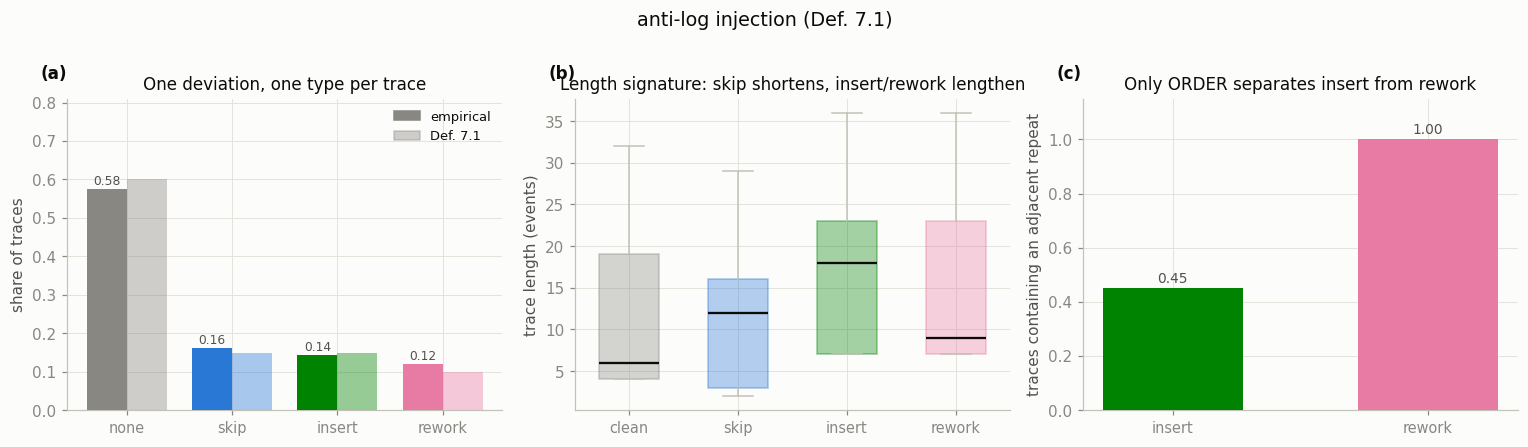

In [7]:
# Fig 2 — the injection procedure: mix, marginals, and the insert/rework ambiguity
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))

ax = axes[0]
counts = Counter(_K1); order = ["none"] + TYPES
vals = [counts.get(k, 0) / len(_K1) for k in order]
exp = [PI["none"], PI["skip"], PI["insert"], PI["rework"]]
w = .38; x = np.arange(len(order))
ax.bar(x - w/2, vals, w, color=[MUTED] + [TCOL[t] for t in TYPES], zorder=3)
ax.bar(x + w/2, exp, w, color=[MUTED] + [TCOL[t] for t in TYPES], alpha=.4, zorder=3)
for i, (a, b) in enumerate(zip(vals, exp)):
    ax.text(i - w/2, a + .012, f"{a:.2f}", ha="center", fontsize=8, color=INK2)
ax.set_xticks(x, order, fontsize=9.5); ax.set_ylim(0, max(exp) * 1.35)
ax.set_ylabel("share of traces")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=MUTED),
                   plt.Rectangle((0, 0), 1, 1, color=MUTED, alpha=.4)],
          labels=["empirical", "Def. 7.1"], fontsize=8.5, loc="upper right")
ax.set_title("One deviation, one type per trace")

ax = axes[1]
lab = ["clean", "skip", "insert", "rework"]
data = [[len(t) for t, k in zip(_X, _K) if k == g] for g in ["none"] + TYPES]
bp = ax.boxplot(data, positions=range(4), widths=.55, patch_artist=True,
                medianprops={"color": INK, "lw": 1.5}, whiskerprops={"color": AXIS},
                capprops={"color": AXIS}, flierprops={"markersize": 2.5,
                "markerfacecolor": MUTED, "markeredgecolor": "none"})
for p, c in zip(bp["boxes"], [MUTED] + [TCOL[t] for t in TYPES]):
    p.set(facecolor=c, alpha=.35, edgecolor=c, linewidth=1.2)
ax.set_xticks(range(4), lab, fontsize=9.5); ax.set_ylabel("trace length (events)")
ax.set_title("Length signature: skip shortens, insert/rework lengthen")

ax = axes[2]
def bag(t): return Counter(t)
same = sum(1 for x, k in zip(_X, _K) if k in ("insert", "rework"))
ins = [x for x, k in zip(_X, _K) if k == "insert"]
rew = [x for x, k in zip(_X, _K) if k == "rework"]
adj_i = np.mean([any(a == b for a, b in zip(t, t[1:])) for t in ins]) if ins else 0
adj_r = np.mean([any(a == b for a, b in zip(t, t[1:])) for t in rew]) if rew else 0
ax.bar([0, 1], [adj_i, adj_r], .55, color=[TCOL["insert"], TCOL["rework"]], zorder=3)
for i, v in enumerate([adj_i, adj_r]):
    ax.text(i, v + .02, f"{v:.2f}", ha="center", fontsize=9, color=INK2)
ax.set_xticks([0, 1], ["insert", "rework"], fontsize=9.5); ax.set_ylim(0, 1.15)
ax.set_ylabel("traces containing an adjacent repeat")
ax.set_title("Only ORDER separates insert from rework")
fig.suptitle("anti-log injection (Def. 7.1)", fontsize=12.5, color=INK, y=1.03)
plt.tight_layout(); label_panels(fig); save_fig(fig, "fig2_antilogs"); plt.show()

## 4 · The Poisson surrogate and its loss

In [8]:
# ── loss (Th. 4.1 + Def. 8.1 + eq. 18) ───────────────────────────────────────
def poisson_nll(lam, y):
    return (lam - y * torch.log(lam + 1e-8)).sum(1).mean()

def calib_penalty(lam, y):
    var = ((y - y.mean(0, keepdim=True)) ** 2).mean(0)      # empirical Var over the batch
    return ((var - lam.mean(0)) ** 2).sum()

def total_loss(lam, y, alpha=ALPHA):
    return poisson_nll(lam, y) + alpha * calib_penalty(lam, y)

# ── fitness and decision (eq. 14, 16, Def. 6.4, Prop. 6.3) ───────────────────
def fitness(lam):        return np.exp(-lam.sum(1))
def flag(lam, tau):      return (fitness(lam) < tau).astype(int)
def dominant_type(lam):  return np.argmax(lam, axis=1)
def severity(fit):
    return np.where(fit < 0.40, "HIGH", np.where(fit < 0.70, "MEDIUM", "conforming"))

# ── encoders ─────────────────────────────────────────────────────────────────
class MLPPoisson(nn.Module):
    "Bag of activities -> hidden stack -> 3 softplus rates. Order-blind (control)."
    def __init__(s, dim, hidden=(128, 64), n=3):
        super().__init__(); L = []; d = dim
        for h in hidden: L += [nn.Linear(d, h), nn.ReLU()]; d = h
        L += [nn.Linear(d, n), nn.Softplus()]
        s.net = nn.Sequential(*L)
    def forward(s, x, L=None): return s.net(x)

class RNNPoisson(nn.Module):
    "Embedding -> (Bi)GRU/(Bi)LSTM stack -> MLP head -> 3 softplus rates."
    def __init__(s, vocab, kind="lstm", layers=1, hidden=64, emb=32, bidir=False, n=3):
        super().__init__()
        s.kind, s.bidir, s.layers = kind, bidir, layers
        s.emb = nn.Embedding(vocab, emb, padding_idx=0)
        s.rnn = {"gru": nn.GRU, "lstm": nn.LSTM}[kind](
            emb, hidden, num_layers=layers, batch_first=True, bidirectional=bidir)
        d = hidden * (2 if bidir else 1)
        s.head = nn.Sequential(nn.Linear(d, 32), nn.ReLU(), nn.Linear(32, n), nn.Softplus())
    def forward(s, x, L):
        e = s.emb(x)
        p = pack_padded_sequence(e, L.cpu(), batch_first=True, enforce_sorted=False)
        out = s.rnn(p)[1]
        h = out[0] if s.kind == "lstm" else out
        h = torch.cat([h[-2], h[-1]], dim=1) if s.bidir else h[-1]
        return s.head(h)

def n_params(m): return sum(p.numel() for p in m.parameters())

# ── features ─────────────────────────────────────────────────────────────────
def make_vocab(traces): return {a: i + 2 for i, a in enumerate(sorted({a for t in traces for a in t}))}
def feat_bag(tr, a2i):
    v = np.zeros(len(a2i) + 3, dtype=np.float32)
    for a in tr: v[a2i.get(a, 1)] += 1
    v[-1] = len(tr) / MAXLEN; return v
def enc_seq(tr, a2i): return [a2i.get(a, 1) for a in tr]

def build(spec, a2i, dev=None):
    dev = dev or DEVICE
    if spec["family"] == "mlp":
        return MLPPoisson(len(a2i) + 3, hidden=spec["hidden"]).to(dev)
    return RNNPoisson(len(a2i) + 2, kind=spec["family"], layers=spec["layers"],
                      hidden=spec["hidden"], emb=spec["emb"], bidir=spec["bidir"]).to(dev)

def to_batch(family, X, a2i, dev=None):
    dev = dev or DEVICE
    if family == "mlp":
        return torch.tensor(np.stack([feat_bag(t, a2i) for t in X])).to(dev), None
    seqs = [torch.tensor(enc_seq(t, a2i)) for t in X]
    Ls = torch.tensor([len(s) for s in seqs])
    return pad_sequence(seqs, batch_first=True).to(dev), Ls

def fwd(family, m, X, a2i, dev=None):
    x, L = to_batch(family, X, a2i, dev); return m(x, L)

@torch.no_grad()
def predict(family, m, X, a2i, bs=512, dev=None):
    m.eval(); t0 = time.perf_counter(); out = []
    for b in range(0, len(X), bs):
        out.append(fwd(family, m, X[b:b+bs], a2i, dev).cpu().numpy())
    lam = np.concatenate(out) if out else np.zeros((0, 3))
    return lam, (time.perf_counter() - t0) * 1000 / max(1, len(X))

def calib_tau(fit, y, n=200):
    "Threshold on the FITNESS maximising F1 (eq. 16 with a fitted tau)."
    if len(np.unique(y)) < 2: return TAU_DOC
    best, bf = TAU_DOC, -1.0
    for tau in np.linspace(max(1e-4, fit.min()), min(1.0, fit.max()), n):
        f = f1_score(y, (fit < tau).astype(int), zero_division=0)
        if f > bf: bf, best = f, float(tau)
    return best

def train(spec, Xtr, Ctr, a2i, epochs, val=None, lr=1e-3, bs=64, track=False):
    m = build(spec, a2i); ys = torch.tensor(Ctr, dtype=torch.float)
    opt = torch.optim.AdamW(m.parameters(), lr=lr)
    idx = np.arange(len(Xtr)); hist = {"epoch": [], "loss": [], "nll": [], "val_f1": []}
    for ep in range(epochs):
        np.random.shuffle(idx); m.train(); tl = nl = 0.0; nb = 0
        for b in range(0, len(idx), bs):
            bi = idx[b:b+bs]; y = ys[bi].to(DEVICE); opt.zero_grad()
            lam = fwd(spec["family"], m, [Xtr[i] for i in bi], a2i)
            nll = poisson_nll(lam, y); loss = nll + ALPHA * calib_penalty(lam, y)
            loss.backward(); opt.step()
            tl += float(loss.item()); nl += float(nll.item()); nb += 1
        if track:
            hist["epoch"].append(ep + 1); hist["loss"].append(tl / max(1, nb))
            hist["nll"].append(nl / max(1, nb))
            if val is not None:
                Xv, yv = val
                lv, _ = predict(spec["family"], m, Xv, a2i)
                hist["val_f1"].append(f1_score(yv, flag(lv, TAU_DOC), zero_division=0))
    return (m, hist) if track else m

print("loss, fitness, encoders and training loop ready")

loss, fitness, encoders and training loop ready


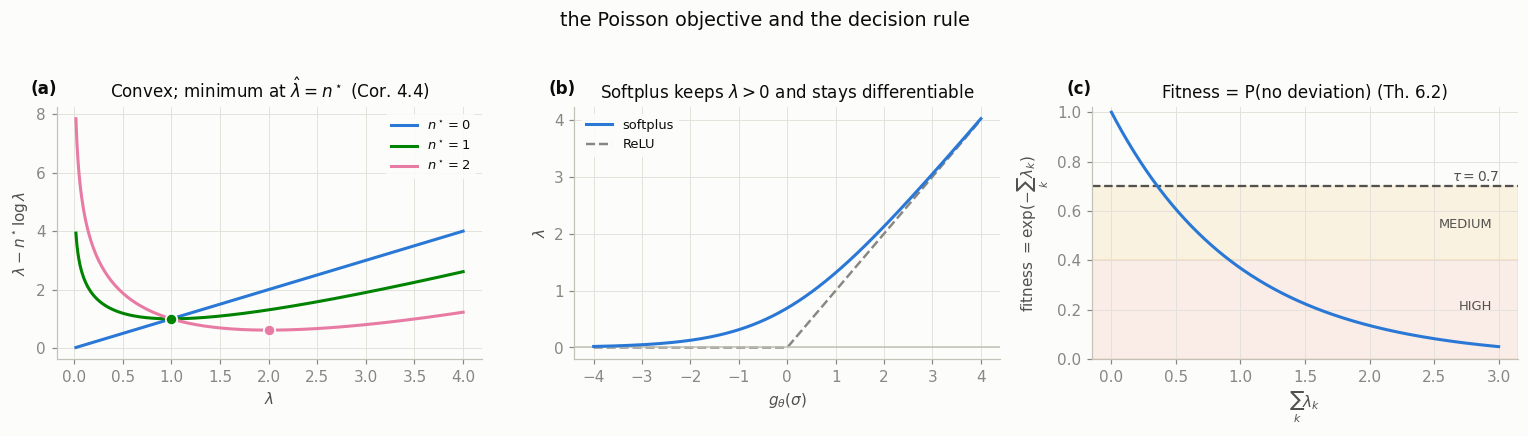

In [9]:
# Fig 3 — properties of the loss, straight from the documentation
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
lam = np.linspace(0.02, 4, 400)

ax = axes[0]
for j, nstar in enumerate([0, 1, 2]):
    L = lam - nstar * np.log(lam)
    ax.plot(lam, L, lw=2, color=CAT[j], label=f"$n^\\star={nstar}$", zorder=3)
    if nstar > 0:
        ax.scatter([nstar], [nstar - nstar * np.log(nstar)], s=55, color=CAT[j],
                   zorder=4, edgecolor=SURF, linewidth=1.2)
ax.set_xlabel("$\\lambda$"); ax.set_ylabel("$\\lambda - n^\\star\\log\\lambda$")
ax.set_title("Convex; minimum at $\\hat\\lambda = n^\\star$ (Cor. 4.4)")
legend_on_data(ax, loc="upper right")

ax = axes[1]
z = np.linspace(-4, 4, 300)
ax.plot(z, np.log1p(np.exp(z)), lw=2, color=CAT[0], label="softplus", zorder=3)
ax.plot(z, np.maximum(z, 0), lw=1.6, ls="--", color=MUTED, label="ReLU", zorder=2)
ax.axhline(0, color=AXIS, lw=1)
ax.set_xlabel("$g_\\theta(\\sigma)$"); ax.set_ylabel("$\\lambda$")
ax.set_title("Softplus keeps $\\lambda>0$ and stays differentiable")
legend_on_data(ax, loc="upper left")

ax = axes[2]
s = np.linspace(0, 3, 300)
ax.plot(s, np.exp(-s), lw=2, color=CAT[0], zorder=3)
ax.axhline(TAU_DOC, color=ORACLE, lw=1.5, ls="--", zorder=2)
ax.text(3, TAU_DOC + .02, f"$\\tau={TAU_DOC}$", ha="right", fontsize=9, color=ORACLE)
ax.axhspan(0, 0.40, color=CAT[5], alpha=.10)
ax.axhspan(0.40, 0.70, color=CAT[3], alpha=.10)
ax.text(2.95, 0.20, "HIGH", ha="right", fontsize=8.5, color=INK2)
ax.text(2.95, 0.53, "MEDIUM", ha="right", fontsize=8.5, color=INK2)
ax.set_xlabel("$\\sum_k \\lambda_k$"); ax.set_ylabel("fitness $=\\exp(-\\sum_k\\lambda_k)$")
ax.set_ylim(0, 1.02); ax.set_title("Fitness = P(no deviation) (Th. 6.2)")
fig.suptitle("the Poisson objective and the decision rule",
             fontsize=12.5, color=INK, y=1.03)
plt.tight_layout(); label_panels(fig); save_fig(fig, "fig3_loss"); plt.show()

## 5 · Data preparation and oracle labelling

In [10]:
DATA = {}
for cfg in CFGS:
    print(f"\n{'='*62}\n  pdc2021_{cfg}\n{'='*62}")
    net, im, fm = load_model(cfg)
    clean = [t for t in load_clean(cfg, N_CLEAN) if 3 <= len(t) <= MAXLEN]
    c_tr, c_va, c_te = split_clean(clean)
    Xtr, Ctr, Ktr = build_antilog(c_tr, seed=SEED)
    Xva, Cva, Kva = build_antilog(c_va, seed=SEED + 1)
    Xte, Cte, Kte = build_antilog(c_te, seed=SEED + 2)
    a2i = make_vocab(Xtr)

    t0 = time.perf_counter(); ok_v, yv, _, _ = astar_labels(Xva, net, im, fm); t_va = time.perf_counter() - t0
    t0 = time.perf_counter(); ok_t, yt, ft, _ = astar_labels(Xte, net, im, fm); t_te = time.perf_counter() - t0

    DATA[cfg] = dict(net=(net, im, fm), a2i=a2i, clean=clean,
                     Xtr=Xtr, Ctr=Ctr, Ktr=Ktr, ytr_inj=(Ctr.sum(1) > 0).astype(int),
                     Xva=[Xva[i] for i in ok_v], Cva=Cva[ok_v], Kva=Kva[ok_v], yva=yv,
                     Xte=[Xte[i] for i in ok_t], Cte=Cte[ok_t], Kte=Kte[ok_t], yte=yt,
                     oracle_s=t_va + t_te)
    agree = accuracy_score((Cte[ok_t].sum(1) > 0).astype(int), yt)
    print(f"  train={len(Xtr)}  val={len(ok_v)}  test={len(ok_t)}  | vocab={len(a2i)}")
    print(f"  A* labelling: {t_va+t_te:.1f}s for {len(yv)+len(yt)} traces "
          f"({1000*(t_va+t_te)/max(1,len(yv)+len(yt)):.1f} ms/trace)")
    print(f"  deviant per A*: {yt.mean():.0%} | injection~A* agreement: {agree:.1%}")


  pdc2021_000000


  train=3600  val=1200  test=1200  | vocab=50
  A* labelling: 6.4s for 2400 traces (2.7 ms/trace)
  deviant per A*: 40% | injection~A* agreement: 100.0%

  pdc2021_100000


  train=3600  val=1200  test=1200  | vocab=50
  A* labelling: 6.8s for 2400 traces (2.8 ms/trace)
  deviant per A*: 38% | injection~A* agreement: 100.0%

  pdc2021_011010


  train=3084  val=1032  test=1032  | vocab=60
  A* labelling: 9.0s for 2064 traces (4.4 ms/trace)
  deviant per A*: 42% | injection~A* agreement: 99.9%

  pdc2021_121111


  train=2418  val=810  test=810  | vocab=39
  A* labelling: 11.3s for 1620 traces (7.0 ms/trace)
  deviant per A*: 40% | injection~A* agreement: 98.0%


## 5b · How hard is the task? — the severity sweep

In [11]:
sev_rows = []
sev_spec = {"family": "gru", "hidden": 128, "layers": 1, "emb": 64, "bidir": False,
            "name": "GRU L1 h128"}
cfg_s = SEARCH_CFGS[0]
clean_s = [t for t in load_clean(cfg_s, N_CLEAN) if 3 <= len(t) <= MAXLEN]
c_tr, c_va, c_te = split_clean(clean_s)
net_s, im_s, fm_s = load_model(cfg_s)

for mag in SEV_GRID:
    Xtr, Ctr, _ = build_antilog(c_tr, seed=SEED, magnitude=mag)
    Xte, Cte, _ = build_antilog(c_te, seed=SEED + 2, magnitude=mag)
    a2i = make_vocab(Xtr)
    ok, y_as, _, _ = astar_labels(Xte, net_s, im_s, fm_s)
    Xte_o, Cte_o = [Xte[i] for i in ok], Cte[ok]
    for fam in ARCHS:
        spec = dict(sev_spec); spec["family"] = fam
        if fam == "mlp": spec = {"family": "mlp", "hidden": (256, 128), "layers": 2,
                                 "emb": 0, "bidir": False, "name": "MLP 256-128"}
        m = train(spec, Xtr, Ctr, a2i, EPOCHS)
        lam_tr, _ = predict(fam, m, Xtr, a2i)
        tau = calib_tau(fitness(lam_tr), (Ctr.sum(1) > 0).astype(int))
        lam_te, _ = predict(fam, m, Xte_o, a2i)
        row = {"magnitude": str(mag), "model": LABEL[fam], "family": fam,
               "mean ops/deviant": round(float(Ctr.sum(1)[Ctr.sum(1) > 0].mean()), 2),
               "F1 vs A*": round(f1_score(y_as, flag(lam_te, tau), zero_division=0), 3)}
        for k, t in enumerate(TYPES):
            grid = np.linspace(lam_tr[:, k].min(), lam_tr[:, k].max(), 120)
            ytr_k = (Ctr[:, k] > 0).astype(int)
            bt, bf = float(np.median(lam_tr[:, k])), -1
            for tk in grid:
                f = f1_score(ytr_k, (lam_tr[:, k] > tk).astype(int), zero_division=0)
                if f > bf: bf, bt = f, float(tk)
            row[f"F1 {t}"] = round(f1_score((Cte_o[:, k] > 0).astype(int),
                                            (lam_te[:, k] > bt).astype(int), zero_division=0), 3)
        sev_rows.append(row)
        del m
        if DEVICE == "cuda": torch.cuda.empty_cache()
    print(f"  magnitude {str(mag):5s} done ({row['mean ops/deviant']} ops per deviant trace)")
df_sev = pd.DataFrame(sev_rows); df_sev.to_csv("poisson_severity.csv", index=False)
df_sev.pivot_table(index="magnitude", columns="model",
                   values=["F1 vs A*", "F1 skip", "F1 insert", "F1 rework"]).round(3)

  magnitude 1     done (1.0 ops per deviant trace)


  magnitude 2     done (2.0 ops per deviant trace)


  magnitude 3     done (2.89 ops per deviant trace)


  magnitude prop  done (3.04 ops per deviant trace)


F1 insert               F1 rework               F1 skip         \
model           GRU   LSTM    MLP       GRU   LSTM    MLP     GRU   LSTM   
magnitude                                                                  
1             0.708  0.730  0.652     0.702  0.720  0.593   0.988  0.991   
2             0.853  0.833  0.635     0.852  0.847  0.498   0.989  0.997   
3             0.919  0.956  0.682     0.849  0.911  0.440   0.983  0.997   
prop          0.933  0.933  0.693     0.949  0.940  0.487   0.976  0.979   

                 F1 vs A*                
model        MLP      GRU   LSTM    MLP  
magnitude                                
1          0.924    0.988  0.995  0.998  
2          0.975    0.995  1.000  0.958  
3          0.991    0.995  0.993  0.991  
prop       0.997    0.993  0.998  0.997

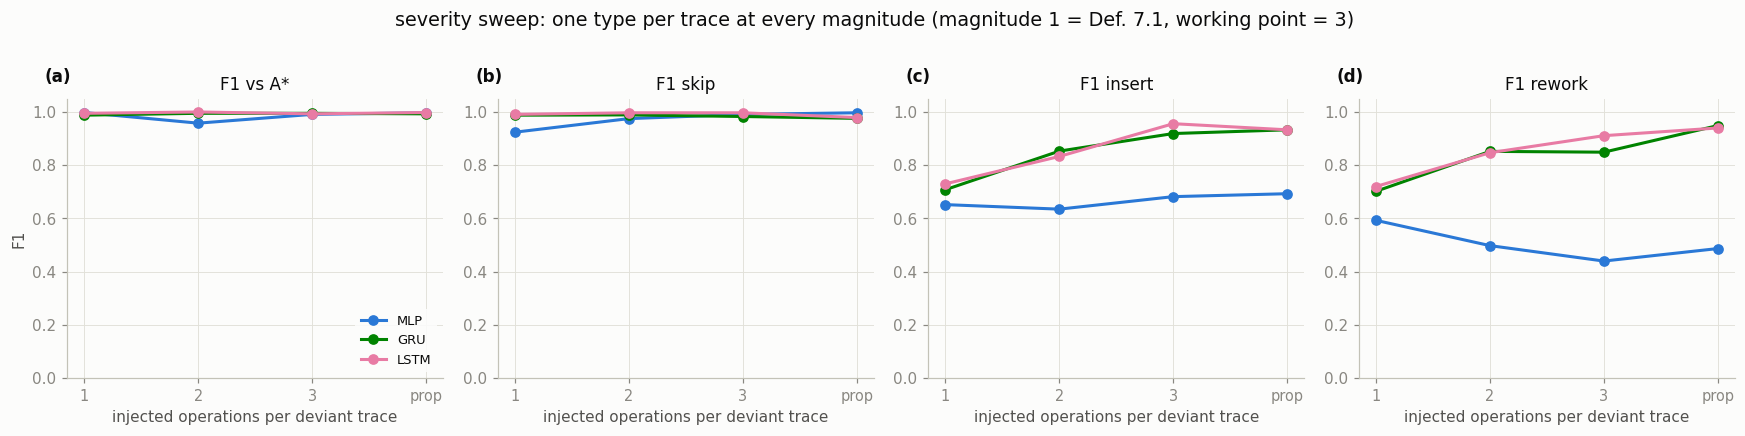

In [12]:
# Fig 3b — difficulty is a property of the task, not only of the model
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
order = [str(s) for s in SEV_GRID]
for j, col in enumerate(["F1 vs A*", "F1 skip", "F1 insert", "F1 rework"]):
    ax = axes[j]
    for fam in ARCHS:
        sub = df_sev[df_sev.family == fam].set_index("magnitude").reindex(order)
        ax.plot(range(len(order)), sub[col].values, marker="o", ms=6, lw=2,
                color=MCOL[fam], label=LABEL[fam], zorder=3)
    ax.set_xticks(range(len(order)), order, fontsize=9.5)
    ax.set_xlabel("injected operations per deviant trace")
    ax.set_ylim(0, 1.05)
    if j == 0: ax.set_ylabel("F1")
    ax.set_title(col)
    if j == 0: legend_on_data(ax, loc="lower right")
fig.suptitle("severity sweep: one type per trace at every magnitude "
             f"(magnitude 1 = Def. 7.1, working point = {MAGNITUDE})",
             fontsize=12.5, color=INK, y=1.03)
plt.tight_layout(); label_panels(fig); save_fig(fig, "fig3b_severity"); plt.show()

## 6 · Architecture search — how deep, how wide, which direction?

In [13]:
SPACE = []
for h in [(64,), (128, 64), (256, 128), (256, 128, 64), (512, 256, 128)]:
    SPACE.append({"family": "mlp", "hidden": h, "layers": len(h), "emb": 0, "bidir": False,
                  "name": f"MLP {'-'.join(map(str, h))}"})
for fam in ["gru", "lstm"]:
    for layers, hid, emb, bi in [(1, 64, 32, False), (1, 128, 64, False),
                                 (2, 128, 64, False), (2, 128, 64, True)]:
        SPACE.append({"family": fam, "hidden": hid, "layers": layers, "emb": emb,
                      "bidir": bi, "name": f"{fam.upper()} L{layers} h{hid}{' bi' if bi else ''}"})
if os.environ.get("SMOKE") == "1": SPACE = [SPACE[0], SPACE[5], SPACE[9]]
print(f"{len(SPACE)} candidate architectures")

srows = []
for spec in SPACE:
    f1s, accs, secs, npar = [], [], [], None
    for cfg in SEARCH_CFGS:
        d = DATA[cfg]
        t0 = time.perf_counter()
        m = train(spec, d["Xtr"], d["Ctr"], d["a2i"], SEARCH_EPOCHS)
        secs.append(time.perf_counter() - t0); npar = n_params(m)
        lam_tr, _ = predict(spec["family"], m, d["Xtr"], d["a2i"])
        tau = calib_tau(fitness(lam_tr), d["ytr_inj"])
        lam_va, _ = predict(spec["family"], m, d["Xva"], d["a2i"])
        pred = flag(lam_va, tau)
        f1s.append(f1_score(d["yva"], pred, zero_division=0))
        accs.append(accuracy_score(d["yva"], pred))
        del m
        if DEVICE == "cuda": torch.cuda.empty_cache()
    srows.append({"architecture": spec["name"], "family": spec["family"],
                  "layers": spec["layers"], "width": (spec["hidden"] if spec["family"] != "mlp"
                                                      else spec["hidden"][0]),
                  "bidir": spec["bidir"], "params": npar,
                  "val F1": float(np.mean(f1s)), "val acc": float(np.mean(accs)),
                  "train s": float(np.mean(secs))})
    print(f"  {spec['name']:22s} params={npar:7d}  val F1={np.mean(f1s):.3f}  "
          f"({np.mean(secs):.0f}s)")
df_search = pd.DataFrame(srows).sort_values("val F1", ascending=False)
df_search.to_csv("poisson_arch_search.csv", index=False)

# The DEPLOYED model must be streaming-eligible: a bidirectional encoder would have to
# re-read the whole prefix on every event, which forfeits the O(1)-per-event property.
# We therefore select the best UNIDIRECTIONAL candidate per family, and keep the best
# overall (possibly bidirectional) only as an offline upper bound.
BEST, BEST_ANY = {}, {}
for fam in ARCHS:
    sub = df_search[df_search.family == fam]
    BEST_ANY[fam] = next(s for s in SPACE if s["name"] == sub.iloc[0]["architecture"])
    uni = sub[~sub.bidir]
    BEST[fam] = next(s for s in SPACE if s["name"] == uni.iloc[0]["architecture"])
    gap = sub.iloc[0]["val F1"] - uni.iloc[0]["val F1"]
    print(f"{LABEL[fam]:5s} deployed: {uni.iloc[0]['architecture']:18s} "
          f"(val F1={uni.iloc[0]['val F1']:.3f})   | best overall: "
          f"{sub.iloc[0]['architecture']:18s} ({sub.iloc[0]['val F1']:.3f}, "
          f"bidirectional gap {gap:+.3f})")
df_search.set_index("architecture")

13 candidate architectures


  MLP 64                 params=   2947  val F1=0.847  (4s)


  MLP 128-64             params=  13955  val F1=0.894  (4s)


  MLP 256-128            params=  44291  val F1=0.912  (4s)


  MLP 256-128-64         params=  52355  val F1=0.904  (4s)


  MLP 512-256-128        params= 186627  val F1=0.925  (5s)


... (5 outputs left out)

  LSTM L1 h128           params= 106179  val F1=0.927  (7s)


  LSTM L2 h128           params= 238275  val F1=0.927  (8s)


  LSTM L2 h128 bi        params= 604867  val F1=0.951  (13s)
MLP   deployed: MLP 512-256-128    (val F1=0.925)   | best overall: MLP 512-256-128    (0.925, bidirectional gap +0.000)
GRU   deployed: GRU L2 h128        (val F1=0.940)   | best overall: GRU L2 h128 bi     (0.962, bidirectional gap +0.021)
LSTM  deployed: LSTM L2 h128       (val F1=0.927)   | best overall: LSTM L2 h128 bi    (0.951, bidirectional gap +0.024)


,family,layers,width,bidir,params,val F1,val acc,train s
architecture,,,,,,,,
GRU L2 h128 bi,gru,2,128,True,456387,0.961508,0.970772,13.030678
LSTM L2 h128 bi,lstm,2,128,True,604867,0.951178,0.964198,13.404537
GRU L2 h128,gru,2,128,False,180419,0.940052,0.953889,7.978566
LSTM L2 h128,lstm,2,128,False,238275,0.927126,0.944645,8.357292
LSTM L1 h128,lstm,1,128,False,106179,0.926667,0.945679,6.616233
MLP 512-256-128,mlp,3,512,False,186627,0.924896,0.942160,4.521052
GRU L1 h128,gru,1,128,False,81347,0.921518,0.941127,6.117067
GRU L1 h64,gru,1,64,False,22307,0.914436,0.935170,6.034048
LSTM L1 h64,lstm,1,64,False,28579,0.913748,0.929830,6.409847


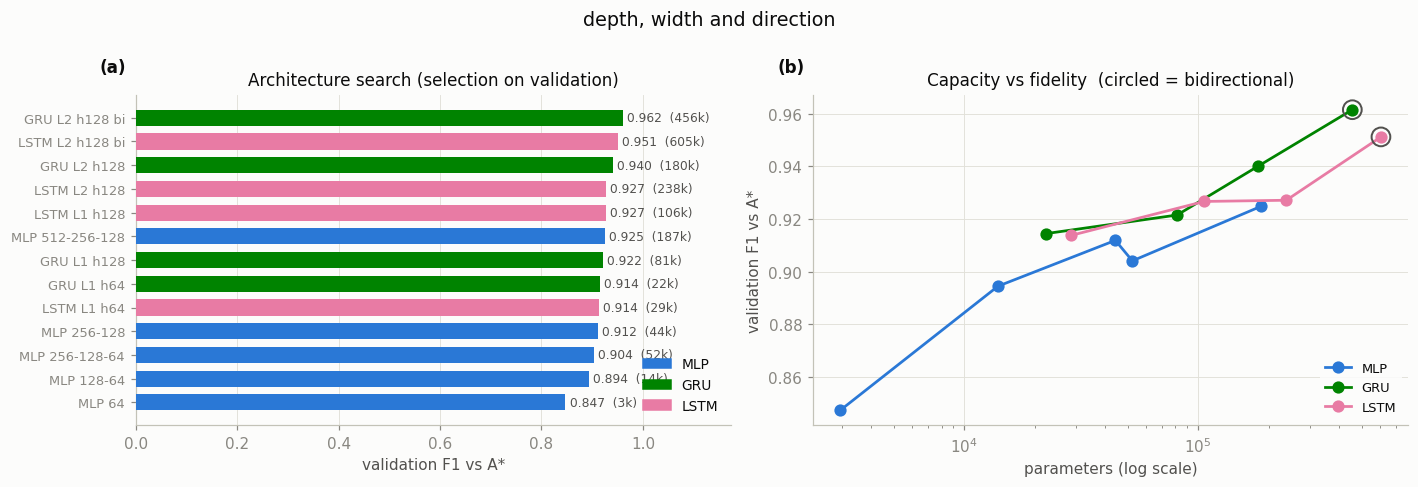

In [14]:
# Fig 4 — what the search found
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
d = df_search.sort_values("val F1")
y = np.arange(len(d))
cols = [MCOL[f] for f in d.family]
ax.barh(y, d["val F1"], .68, color=cols, zorder=3)
for i, (v, p) in enumerate(zip(d["val F1"], d["params"])):
    ax.text(v + .008, i, f"{v:.3f}  ({p/1000:.0f}k)", va="center", fontsize=8, color=INK2)
ax.set_yticks(y, d["architecture"], fontsize=8.5)
ax.set_xlim(0, max(d["val F1"]) * 1.22); ax.set_xlabel("validation F1 vs A*")
ax.set_title("Architecture search (selection on validation)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=MCOL[f]) for f in ARCHS],
          labels=[LABEL[f] for f in ARCHS], fontsize=9, loc="lower right")
ax.grid(axis="y", visible=False)

ax = axes[1]
for fam in ARCHS:
    sub = df_search[df_search.family == fam].sort_values("params")
    ax.plot(sub["params"], sub["val F1"], marker="o", ms=7, lw=1.8,
            color=MCOL[fam], label=LABEL[fam], zorder=3)
    for _, r in sub.iterrows():
        if r["bidir"]:
            ax.scatter([r["params"]], [r["val F1"]], s=150, facecolor="none",
                       edgecolor=INK2, linewidth=1.3, zorder=4)
ax.set_xscale("log"); ax.set_xlabel("parameters (log scale)")
ax.set_ylabel("validation F1 vs A*")
ax.set_title("Capacity vs fidelity  (circled = bidirectional)")
legend_on_data(ax, loc="lower right")
fig.suptitle("depth, width and direction", fontsize=12.5, color=INK, y=1.02)
plt.tight_layout(); label_panels(fig); save_fig(fig, "fig4_search"); plt.show()

## 7 · Training the selected models and measuring them

In [15]:
MODELS = {}; HIST = {}
for cfg in CFGS:
    d = DATA[cfg]; MODELS[cfg] = {}; HIST[cfg] = {}
    print(f"\n--- pdc2021_{cfg} ---")
    for fam in ARCHS:
        spec = BEST[fam]; t0 = time.perf_counter()
        m, h = train(spec, d["Xtr"], d["Ctr"], d["a2i"], EPOCHS,
                     val=(d["Xva"], d["yva"]), track=True)
        h["train_s"] = time.perf_counter() - t0; h["params"] = n_params(m)
        MODELS[cfg][fam] = m; HIST[cfg][fam] = h
        print(f"  {spec['name']:22s} {h['train_s']:5.1f}s | NLL={h['nll'][-1]:.3f} "
              f"| val F1={h['val_f1'][-1]:.3f}")


--- pdc2021_000000 ---


  MLP 512-256-128         11.6s | NLL=0.322 | val F1=0.999


  GRU L2 h128             18.6s | NLL=-0.046 | val F1=0.999


  LSTM L2 h128            19.5s | NLL=-0.014 | val F1=1.000

--- pdc2021_100000 ---


  MLP 512-256-128         11.6s | NLL=0.336 | val F1=0.995


  GRU L2 h128             18.5s | NLL=0.011 | val F1=0.990


... (3 outputs left out)

  LSTM L2 h128            23.0s | NLL=0.178 | val F1=0.918

--- pdc2021_121111 ---


  MLP 512-256-128          9.0s | NLL=0.456 | val F1=0.821


  GRU L2 h128             15.9s | NLL=0.143 | val F1=0.876


  LSTM L2 h128            15.4s | NLL=0.183 | val F1=0.867


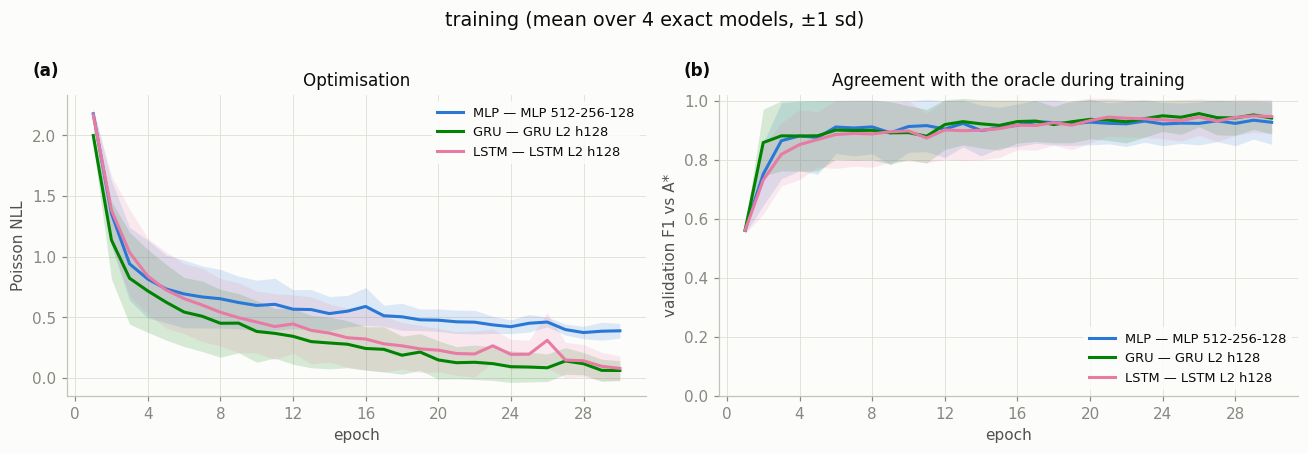

In [16]:
# Fig 5 — training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ep = np.arange(1, EPOCHS + 1)
for fam in ARCHS:
    N = np.array([HIST[c][fam]["nll"] for c in CFGS])
    F = np.array([HIST[c][fam]["val_f1"] for c in CFGS])
    for ax, M in ((axes[0], N), (axes[1], F)):
        mu, sd = M.mean(0), M.std(0)
        ax.plot(ep, mu, lw=2, color=MCOL[fam], label=f"{LABEL[fam]} — {BEST[fam]['name']}", zorder=3)
        if len(CFGS) > 1:
            ax.fill_between(ep, mu - sd, mu + sd, color=MCOL[fam], alpha=.15, lw=0, zorder=2)
for ax in axes: ax.set_xlabel("epoch"); ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0].set_ylabel("Poisson NLL"); axes[0].set_title("Optimisation")
legend_on_data(axes[0], loc="upper right")
axes[1].set_ylabel("validation F1 vs A*"); axes[1].set_ylim(0, 1.02)
axes[1].set_title("Agreement with the oracle during training")
legend_on_data(axes[1], loc="lower right")
fig.suptitle(f"training (mean over {len(CFGS)} exact models, ±1 sd)",
             fontsize=12.5, color=INK, y=1.02)
plt.tight_layout(); label_panels(fig); save_fig(fig, "fig5_training"); plt.show()

## 8 · Metrics

In [17]:
mrows = []; ROC = {}; PERTYPE = {}
for cfg in CFGS:
    d = DATA[cfg]; ROC[cfg] = {}; PERTYPE[cfg] = {}
    gt = GT_CACHE.get(cfg) or load_gt(cfg)
    gtX = [t[0] for t in gt]; gtY = np.array([t[1] for t in gt])
    for fam in ARCHS:
        m = MODELS[cfg][fam]
        lam_tr, _ = predict(fam, m, d["Xtr"], d["a2i"])
        tau = calib_tau(fitness(lam_tr), d["ytr_inj"])
        lam_te, ms = predict(fam, m, d["Xte"], d["a2i"])
        fit = fitness(lam_te); pred = (fit < tau).astype(int); y = d["yte"]
        try:    auc = roc_auc_score(y, -fit); ap = average_precision_score(y, -fit)
        except Exception: auc, ap = np.nan, np.nan
        ROC[cfg][fam] = (y, -fit)
        row = {"config": cfg, "model": LABEL[fam], "family": fam,
               "architecture": BEST[fam]["name"], "params": n_params(m),
               "accuracy": round(accuracy_score(y, pred), 3),
               "F1 vs A*": round(f1_score(y, pred, zero_division=0), 3),
               "ROC-AUC": round(auc, 3) if auc == auc else np.nan,
               "MAE counts": round(mean_absolute_error(d["Cte"], lam_te), 3),
               "tau": round(tau, 3), "ms/trace": round(ms, 4)}
        # per-type detection, against the injection ground truth
        pt = {}
        for k, t in enumerate(TYPES):
            tk_grid = np.linspace(lam_tr[:, k].min(), lam_tr[:, k].max(), 200)
            ytr_k = (d["Ctr"][:, k] > 0).astype(int)
            best_t, best_f = float(np.median(lam_tr[:, k])), -1
            for tk in tk_grid:
                f = f1_score(ytr_k, (lam_tr[:, k] > tk).astype(int), zero_division=0)
                if f > best_f: best_f, best_t = f, float(tk)
            yk = (d["Cte"][:, k] > 0).astype(int); pk = (lam_te[:, k] > best_t).astype(int)
            row[f"F1 {t}"] = round(f1_score(yk, pk, zero_division=0), 3)
            pt[t] = {"y": yk, "score": lam_te[:, k],
                     "P": precision_score(yk, pk, zero_division=0),
                     "R": recall_score(yk, pk, zero_division=0)}
        PERTYPE[cfg][fam] = pt
        # dominant-type attribution among traces A* and injection agree are deviant
        dev = (d["Cte"].sum(1) > 0)
        if dev.sum():
            true_k = np.argmax(d["Cte"][dev], axis=1)
            pred_k = dominant_type(lam_te[dev])
            row["type accuracy"] = round(accuracy_score(true_k, pred_k), 3)
        lam_gt, _ = predict(fam, m, gtX, d["a2i"])
        row["F1 real GT"] = round(f1_score(gtY, (fitness(lam_gt) < tau).astype(int),
                                           zero_division=0), 3)
        mrows.append(row)
        print(f"  pdc_{cfg} {LABEL[fam]:5s} F1={row['F1 vs A*']:.3f} AUC={row['ROC-AUC']} "
              f"| skip={row['F1 skip']:.3f} insert={row['F1 insert']:.3f} "
              f"rework={row['F1 rework']:.3f} | realGT={row['F1 real GT']:.3f}")
df_metrics = pd.DataFrame(mrows); df_metrics.to_csv("poisson_metrics.csv", index=False)
df_metrics.drop(columns=["family"]).set_index(["config", "model"])

  pdc_000000 MLP   F1=0.991 AUC=1.0 | skip=0.972 insert=0.645 rework=0.454 | realGT=0.975


  pdc_000000 GRU   F1=0.996 AUC=1.0 | skip=0.991 insert=0.956 rework=0.920 | realGT=0.884


  pdc_000000 LSTM  F1=0.994 AUC=1.0 | skip=0.991 insert=0.944 rework=0.922 | realGT=0.889


  pdc_100000 MLP   F1=0.993 AUC=1.0 | skip=0.997 insert=0.684 rework=0.482 | realGT=0.988


  pdc_100000 GRU   F1=0.986 AUC=0.998 | skip=0.990 insert=0.849 rework=0.782 | realGT=0.933


  pdc_100000 LSTM  F1=0.998 AUC=1.0 | skip=0.997 insert=0.933 rework=0.916 | realGT=0.853


... (3 outputs left out)

  pdc_121111 MLP   F1=0.841 AUC=0.943 | skip=0.726 insert=0.517 rework=0.456 | realGT=0.651


  pdc_121111 GRU   F1=0.901 AUC=0.976 | skip=0.805 insert=0.782 rework=0.781 | realGT=0.780


  pdc_121111 LSTM  F1=0.892 AUC=0.97 | skip=0.837 insert=0.775 rework=0.780 | realGT=0.828


architecture  params  accuracy  F1 vs A*  ROC-AUC  \
config model                                                         
000000 MLP    MLP 512-256-128  192259     0.993     0.991    1.000   
       GRU        GRU L2 h128  181123     0.997     0.996    1.000   
       LSTM      LSTM L2 h128  238979     0.995     0.994    1.000   
100000 MLP    MLP 512-256-128  192259     0.995     0.993    1.000   
       GRU        GRU L2 h128  181123     0.989     0.986    0.998   
       LSTM      LSTM L2 h128  238979     0.998     0.998    1.000   
011010 MLP    MLP 512-256-128  197379     0.911     0.892    0.957   
       GRU        GRU L2 h128  181763     0.968     0.961    0.994   
       LSTM      LSTM L2 h128  239619     0.959     0.951    0.987   
121111 MLP    MLP 512-256-128  186627     0.870     0.841    0.943   
       GRU        GRU L2 h128  180419     0.922     0.901    0.976   
       LSTM      LSTM L2 h128  238275     0.915     0.892    0.970   

              MAE counts    tau  ms/trace  F1 skip  F1 insert  F1 rework  \
config model                                                               
000000 MLP         0.268  0.154    0.0286    0.972      0.645      0.454   
       GRU         0.080  0.131    0.0235    0.991      0.956      0.920   
       LSTM        0.098  0.128    0.0332    0.991      0.944      0.922   
100000 MLP         0.264  0.168    0.0337    0.997      0.684      0.482   
       GRU         0.153  0.847    0.0320    0.990      0.849      0.782   
       LSTM        0.090  0.145    0.0341    0.997      0.933      0.916   
011010 MLP         0.360  0.326    0.0272    0.895      0.552      0.446   
       GRU         0.155  0.251    0.0325    0.953      0.885      0.856   
       LSTM        0.158  0.339    0.0371    0.957      0.853      0.811   
121111 MLP         0.408  0.397    0.0317    0.726      0.517      0.456   
       GRU         0.226  0.254    0.0354    0.805      0.782      0.781   
       LSTM        0.217  0.296    0.0399    0.837      0.775      0.780   

              type accuracy  F1 real GT  
config model                             
000000 MLP            0.713       0.975  
       GRU            0.960       0.884  
       LSTM           0.946       0.889  
100000 MLP            0.711       0.988  
       GRU            0.888       0.933  
       LSTM           0.958       0.853  
011010 MLP            0.602       0.877  
       GRU            0.907       0.794  
       LSTM           0.895       0.893  
121111 MLP            0.576       0.651  
       GRU            0.822       0.780  
       LSTM           0.849       0.828

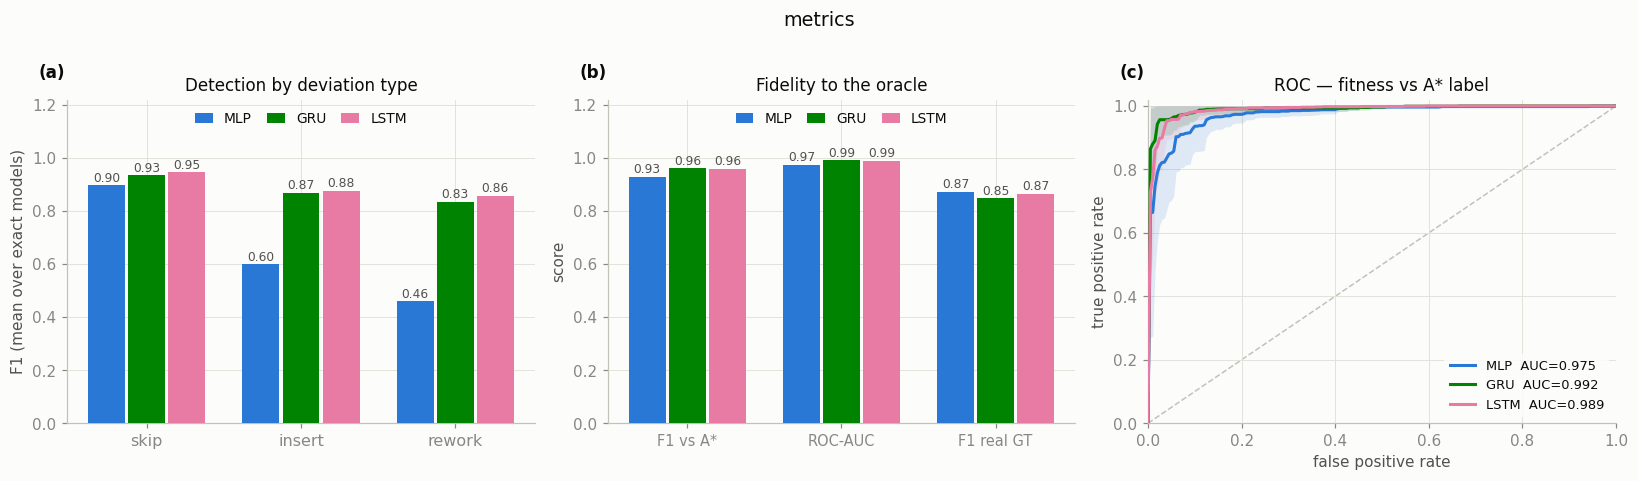

In [18]:
# Fig 6 — the headline per-type figure + overall fidelity
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes[0]
x = np.arange(len(TYPES)); w = .26
for k, fam in enumerate(ARCHS):
    vals = [df_metrics[df_metrics.family == fam][f"F1 {t}"].mean() for t in TYPES]
    b = ax.bar(x + (k - 1) * w, vals, w * .92, color=MCOL[fam], label=LABEL[fam], zorder=3)
    for bb, v in zip(b, vals):
        ax.text(bb.get_x() + bb.get_width()/2, v + .015, f"{v:.2f}", ha="center",
                fontsize=8, color=INK2)
ax.set_xticks(x, TYPES, fontsize=10.5); ax.set_ylim(0, 1.22)
ax.set_ylabel("F1 (mean over exact models)")
ax.set_title("Detection by deviation type")
ax.legend(fontsize=9, loc="upper center", ncol=3, columnspacing=1.1, handlelength=1.3)

ax = axes[1]
for k, fam in enumerate(ARCHS):
    sub = df_metrics[df_metrics.family == fam]
    vals = [sub["F1 vs A*"].mean(), sub["ROC-AUC"].mean(), sub["F1 real GT"].mean()]
    b = ax.bar(np.arange(3) + (k - 1) * w, vals, w * .92, color=MCOL[fam],
               label=LABEL[fam], zorder=3)
    for bb, v in zip(b, vals):
        ax.text(bb.get_x() + bb.get_width()/2, v + .015, f"{v:.2f}", ha="center",
                fontsize=8, color=INK2)
ax.set_xticks(np.arange(3), ["F1 vs A*", "ROC-AUC", "F1 real GT"], fontsize=9.5)
ax.set_ylim(0, 1.22); ax.set_ylabel("score")
ax.set_title("Fidelity to the oracle")
ax.legend(fontsize=9, loc="upper center", ncol=3, columnspacing=1.1, handlelength=1.3)

ax = axes[2]
grid = np.linspace(0, 1, 201)
for fam in ARCHS:
    tprs, aucs = [], []
    for c in CFGS:
        y, s = ROC[c][fam]
        if len(set(y)) < 2: continue
        fpr, tpr, _ = roc_curve(y, s)
        tprs.append(np.interp(grid, fpr, tpr)); aucs.append(roc_auc_score(y, s))
    if not tprs: continue
    mt = np.mean(tprs, 0); mt[0] = 0
    ax.plot(grid, mt, lw=2, color=MCOL[fam], zorder=3,
            label=f"{LABEL[fam]}  AUC={np.mean(aucs):.3f}")
    if len(tprs) > 1:
        sd = np.std(tprs, 0)
        ax.fill_between(grid, np.clip(mt-sd, 0, 1), np.clip(mt+sd, 0, 1),
                        color=MCOL[fam], alpha=.14, lw=0, zorder=2)
ax.plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--", zorder=1)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title("ROC — fitness vs A* label"); legend_on_data(ax, loc="lower right")
fig.suptitle("metrics", fontsize=12.5, color=INK, y=1.03)
plt.tight_layout(); label_panels(fig); save_fig(fig, "fig6_metrics"); plt.show()

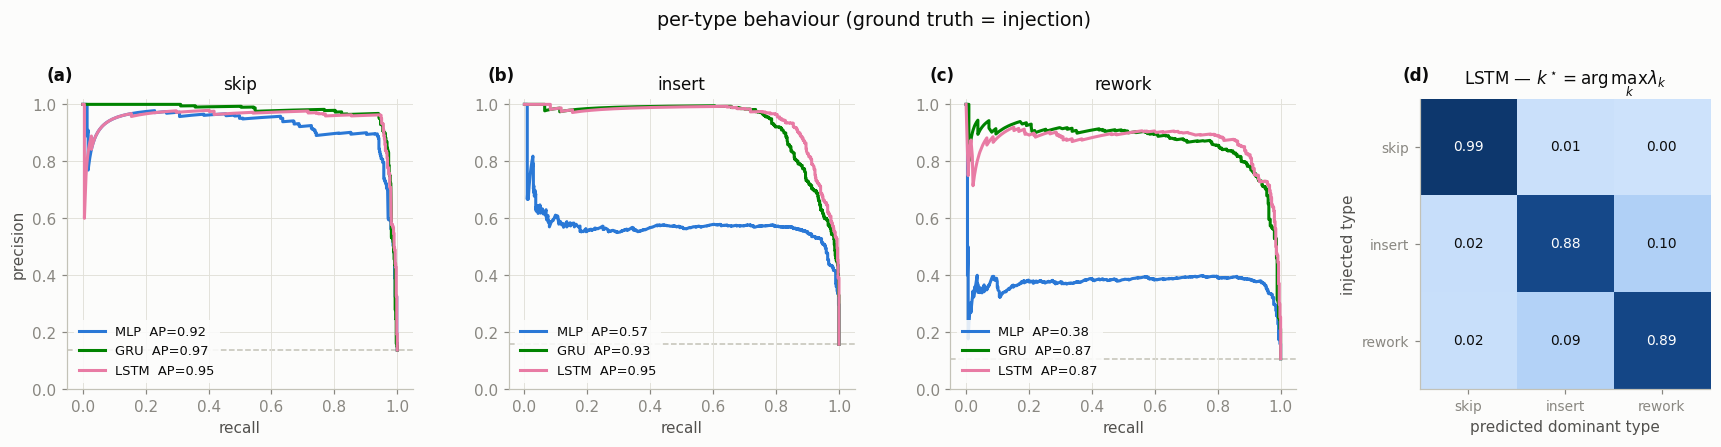

In [19]:
# Fig 7 — where the type signal comes from: per-type PR and the confusion of dominant type
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
for j, t in enumerate(TYPES):
    ax = axes[j]
    for fam in ARCHS:
        ys = np.concatenate([PERTYPE[c][fam][t]["y"] for c in CFGS])
        ss = np.concatenate([PERTYPE[c][fam][t]["score"] for c in CFGS])
        if len(set(ys)) < 2: continue
        pr, rc, _ = precision_recall_curve(ys, ss)
        ax.plot(rc, pr, lw=2, color=MCOL[fam], zorder=3,
                label=f"{LABEL[fam]}  AP={average_precision_score(ys, ss):.2f}")
        base = ys.mean()
    ax.axhline(base, color=AXIS, lw=1, ls="--", zorder=1)
    ax.set_xlabel("recall"); ax.set_ylim(0, 1.02)
    if j == 0: ax.set_ylabel("precision")
    ax.set_title(f"{t}"); legend_on_data(ax, loc="lower left")

ax = axes[3]
fam = "lstm"
M = np.zeros((3, 3))
for c in CFGS:
    d = DATA[c]; lam, _ = predict(fam, MODELS[c][fam], d["Xte"], d["a2i"])
    dev = d["Cte"].sum(1) > 0
    if dev.sum() == 0: continue
    M += confusion_matrix(np.argmax(d["Cte"][dev], axis=1), dominant_type(lam[dev]),
                          labels=[0, 1, 2])
Mn = M / np.maximum(M.sum(1, keepdims=True), 1)
im_ = ax.imshow(Mn, cmap=BLUES, vmin=0, vmax=1)
for i in range(3):
    for j2 in range(3):
        ax.text(j2, i, f"{Mn[i, j2]:.2f}", ha="center", va="center", fontsize=9,
                color="#ffffff" if Mn[i, j2] > .55 else INK)
ax.set_xticks(range(3), TYPES, fontsize=9); ax.set_yticks(range(3), TYPES, fontsize=9)
ax.set_xlabel("predicted dominant type"); ax.set_ylabel("injected type")
ax.set_title(f"{LABEL[fam]} — $k^\\star=\\arg\\max_k\\lambda_k$"); ax.grid(False)
fig.suptitle("per-type behaviour (ground truth = injection)",
             fontsize=12.5, color=INK, y=1.03)
plt.tight_layout(); label_panels(fig); save_fig(fig, "fig7_pertype"); plt.show()

## 9 · Streaming inference

In [20]:
def stream_spec(fam):
    "The deployed models are already unidirectional, so streaming reuses them as-is."
    assert not BEST[fam].get("bidir"), "streaming requires a causal encoder"
    return BEST[fam]

def make_stream(clean, n=STREAM_N, drift_at=.5, seed=SEED):
    "Deviation regime flips at mid-stream (Def. 7.1 operators, re-weighted)."
    rng = random.Random(seed); pool = [t for t in clean if 3 <= len(t) <= MAXLEN]
    X, Cc = [], []
    for i in range(n):
        tr = list(rng.choice(pool)); c = [0, 0, 0]
        pre = i < drift_at * n
        p_dev = 0.40
        if rng.random() < p_dev and len(tr) >= 3:
            kind = (rng.choices(TYPES, weights=(6, 1, 1))[0] if pre
                    else rng.choices(TYPES, weights=(1, 3, 3))[0])
            if kind == "skip":     tr.pop(rng.randrange(len(tr))); c[0] = 1
            elif kind == "insert": tr.insert(rng.randrange(len(tr)+1),
                                             tr[rng.randrange(len(tr))]); c[1] = 1
            else:                  k = rng.randrange(len(tr)); tr.insert(k, tr[k]); c[2] = 1
        X.append(tr); Cc.append(c)
    return X, np.array(Cc, dtype=float)

def _recalib(fam, m, bufX, bufC, a2i):
    lb, _ = predict(fam, m, list(bufX), a2i)
    return calib_tau(fitness(lb), (np.stack(list(bufC)).sum(1) > 0).astype(int))

def run_stream(fam, spec, X, Cc, a2i, adapt=True, warmup=WARMUP, window=PREQ_W,
               lr=1e-3, replay=256, mb=32):
    y = (Cc.sum(1) > 0).astype(int)
    m = train(spec, X[:warmup], Cc[:warmup], a2i, EPOCHS)
    bufX = deque(list(X[:warmup]), maxlen=replay); bufC = deque(list(Cc[:warmup]), maxlen=replay)
    tau = _recalib(fam, m, bufX, bufC, a2i)
    opt = torch.optim.AdamW(m.parameters(), lr=lr)
    buf = deque(maxlen=window); xs, f1c = [], []; tot = 0.0; nstep = 0
    for i in range(warmup, len(X)):
        t0 = time.perf_counter(); m.eval()
        with torch.no_grad(): lam = fwd(fam, m, [X[i]], a2i).cpu().numpy()
        pred = int(fitness(lam)[0] < tau)
        tot += (time.perf_counter() - t0) * 1000; nstep += 1
        buf.append((pred, int(y[i])))
        if adapt:                                              # test-THEN-train
            bufX.append(X[i]); bufC.append(Cc[i])
            bi = np.random.randint(0, len(bufX), size=min(mb, len(bufX)))
            xb = [bufX[j] for j in bi]
            yb = torch.tensor(np.stack([bufC[j] for j in bi]), dtype=torch.float).to(DEVICE)
            m.train(); opt.zero_grad()
            total_loss(fwd(fam, m, xb, a2i), yb).backward(); opt.step()
            if nstep % 25 == 0: tau = _recalib(fam, m, bufX, bufC, a2i)
        if len(buf) == window and i % 10 == 0:
            pr = np.array([b[0] for b in buf]); tr_ = np.array([b[1] for b in buf])
            f1c.append(f1_score(tr_, pr, zero_division=0)); xs.append(i)
    return np.array(xs), np.array(f1c), tot / max(1, nstep)

STREAM = {}
for cfg in STREAM_CFGS:
    d = DATA[cfg]
    X, Cc = make_stream(d["clean"]); a2i = make_vocab(X); STREAM[cfg] = {}
    print(f"\n=== streaming pdc2021_{cfg} ({len(X)} traces) ===")
    for fam in ARCHS:
        spec = stream_spec(fam)
        xs, fz, _  = run_stream(fam, spec, X, Cc, a2i, adapt=False)
        _,  on, ms = run_stream(fam, spec, X, Cc, a2i, adapt=True)
        STREAM[cfg][fam] = {"xs": xs, "frozen": fz, "online": on, "ms": ms,
                            "spec": spec["name"]}
        print(f"  {LABEL[fam]:5s} ({spec['name']:18s}) frozen={fz[-5:].mean():.3f} "
              f"online={on[-5:].mean():.3f} gain=+{on[-5:].mean()-fz[-5:].mean():.3f} "
              f"| {ms:.2f} ms/trace")

df_stream = pd.DataFrame([
    {"config": c, "model": LABEL[f], "architecture": r["spec"],
     "F1 frozen (end)": round(float(np.mean(r["frozen"][-5:])), 3),
     "F1 online (end)": round(float(np.mean(r["online"][-5:])), 3),
     "gain after drift": round(float(np.mean(r["online"][-5:]) - np.mean(r["frozen"][-5:])), 3),
     "ms/trace": round(r["ms"], 2)}
    for c, byf in STREAM.items() for f, r in byf.items()])
df_stream.to_csv("poisson_streaming.csv", index=False)
df_stream


=== streaming pdc2021_000000 (1600 traces) ===


  MLP   (MLP 512-256-128   ) frozen=0.357 online=0.734 gain=+0.377 | 1.44 ms/trace


  GRU   (GRU L2 h128       ) frozen=0.343 online=0.878 gain=+0.535 | 2.33 ms/trace


  LSTM  (LSTM L2 h128      ) frozen=0.506 online=0.839 gain=+0.333 | 1.96 ms/trace

=== streaming pdc2021_121111 (1600 traces) ===


  MLP   (MLP 512-256-128   ) frozen=0.435 online=0.793 gain=+0.358 | 1.31 ms/trace


  GRU   (GRU L2 h128       ) frozen=0.335 online=0.827 gain=+0.492 | 1.95 ms/trace


  LSTM  (LSTM L2 h128      ) frozen=0.575 online=0.816 gain=+0.240 | 2.08 ms/trace


,config,model,architecture,F1 frozen (end),F1 online (end),gain after drift,ms/trace
0,000000,MLP,MLP 512-256-128,0.357,0.734,0.377,1.44
1,000000,GRU,GRU L2 h128,0.343,0.878,0.535,2.33
2,000000,LSTM,LSTM L2 h128,0.506,0.839,0.333,1.96
3,121111,MLP,MLP 512-256-128,0.435,0.793,0.358,1.31
4,121111,GRU,GRU L2 h128,0.335,0.827,0.492,1.95
5,121111,LSTM,LSTM L2 h128,0.575,0.816,0.240,2.08


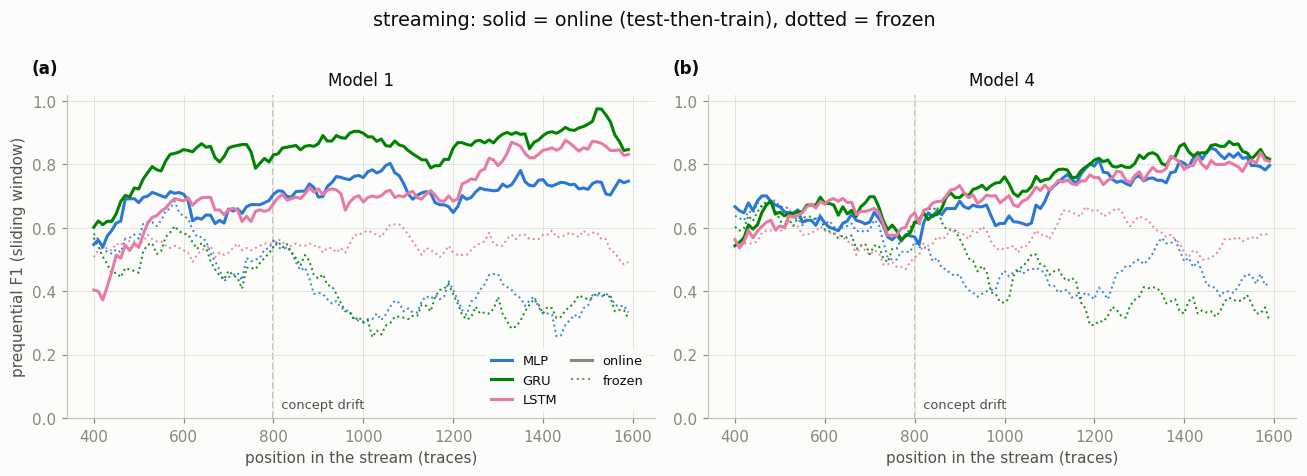

In [21]:
# Fig 8 — prequential F1 with a concept drift at mid-stream
n = len(STREAM)
fig, axes = plt.subplots(1, n, figsize=(max(7.5, 6.0 * n), 4.2), squeeze=False); axes = axes[0]
for ax, (cfg, byf) in zip(axes, STREAM.items()):
    for fam in ARCHS:
        r = byf[fam]
        ax.plot(r["xs"], r["online"], color=MCOL[fam], lw=2, zorder=3)
        ax.plot(r["xs"], r["frozen"], color=MCOL[fam], lw=1.3, ls=":", alpha=.9, zorder=2)
    ax.axvline(STREAM_N * .5, color=AXIS, lw=1.2, ls="--", zorder=1)
    ax.text(STREAM_N * .5, .03, "  concept drift", color=INK2, fontsize=8.5)
    ax.set_title(mname(cfg)); ax.set_xlabel("position in the stream (traces)")
    ax.set_ylim(0, 1.02)
axes[0].set_ylabel("prequential F1 (sliding window)")
legend_on_data(axes[0], loc="lower right", ncol=2, columnspacing=1.1, handlelength=1.6,
               handles=[plt.Line2D([0], [0], color=MCOL[f], lw=2) for f in ARCHS] +
                       [plt.Line2D([0], [0], color=MUTED, lw=2),
                        plt.Line2D([0], [0], color=MUTED, lw=1.4, ls=":")],
               labels=[LABEL[f] for f in ARCHS] + ["online", "frozen"])
fig.suptitle("streaming: solid = online (test-then-train), dotted = frozen",
             fontsize=12.5, color=INK, y=1.02)
plt.tight_layout(); label_panels(fig); save_fig(fig, "fig8_streaming"); plt.show()

## 10 · Speed-up over A\*

In [22]:
@torch.no_grad()
def bench_latency(fam, m, X, a2i, batch=1, dev=None, repeats=5, warm=25):
    dev = dev or DEVICE
    mm = copy.deepcopy(m).to(dev).eval()
    chunks = [X[i:i+batch] for i in range(0, len(X), batch)]
    for i in range(warm): fwd(fam, mm, chunks[i % len(chunks)], a2i, dev)
    if dev == "cuda": torch.cuda.synchronize()
    runs = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        for ch in chunks: fwd(fam, mm, ch, a2i, dev)
        if dev == "cuda": torch.cuda.synchronize()
        runs.append((time.perf_counter() - t0) * 1000 / max(1, len(X)))
    del mm
    if dev == "cuda": torch.cuda.empty_cache()
    return float(np.median(runs))

lrows = []; LAT_A = {}
devs = ["cuda", "cpu"] if DEVICE == "cuda" else ["cpu"]
for cfg in CFGS:
    d = DATA[cfg]; net, im, fm = d["net"]; Xl = d["Xte"][:N_LAT]
    la = astar_per_trace(Xl, net, im, fm); LAT_A[cfg] = la
    lrows.append({"config": cfg, "method": "A*", "family": "astar", "batch": 1,
                  "device": "cpu", "ms/trace": float(la.ms.mean())})
    for fam in ARCHS:
        for bs in BATCHES:
            for dv in devs:
                lrows.append({"config": cfg, "method": LABEL[fam], "family": fam,
                              "batch": bs, "device": dv,
                              "ms/trace": bench_latency(fam, MODELS[cfg][fam], Xl,
                                                        d["a2i"], batch=bs, dev=dv)})
    print(f"  pdc_{cfg}: A* {la.ms.mean():.2f} ms/trace (median {la.ms.median():.2f})")
df_lat = pd.DataFrame(lrows); df_lat.to_csv("poisson_latency.csv", index=False)

astar_ms = df_lat[df_lat.family == "astar"]["ms/trace"].mean()
online = df_lat[(df_lat.batch == 1) & (df_lat.device == DEVICE) & (df_lat.family != "astar")]
tbl = online.groupby("method")["ms/trace"].mean().to_frame("ms/trace (batch=1)")
tbl["speed-up"] = (astar_ms / tbl["ms/trace (batch=1)"]).round(1)
tbl["traces/s"] = (1000 / tbl["ms/trace (batch=1)"]).round(0)
best = df_lat[(df_lat.family != "astar") & (df_lat.device == DEVICE)].groupby("method")["ms/trace"].min()
tbl["batched ms"] = best.round(4); tbl["batched speed-up"] = (astar_ms / best).round(0)
print(f"\nA* reference: {astar_ms:.2f} ms/trace ({1000/astar_ms:.0f} traces/s)")
tbl.reindex([LABEL[f] for f in ARCHS])

  pdc_000000: A* 5.06 ms/trace (median 4.70)


  pdc_100000: A* 5.18 ms/trace (median 4.78)


  pdc_011010: A* 6.30 ms/trace (median 4.75)


  pdc_121111: A* 13.33 ms/trace (median 5.39)

A* reference: 7.47 ms/trace (134 traces/s)


,ms/trace (batch=1),speed-up,traces/s,batched ms,batched speed-up
method,,,,,
MLP,0.426784,17.5,2343.0,0.0339,220.0
GRU,1.678026,4.4,596.0,0.0350,214.0
LSTM,1.632211,4.6,613.0,0.0342,218.0


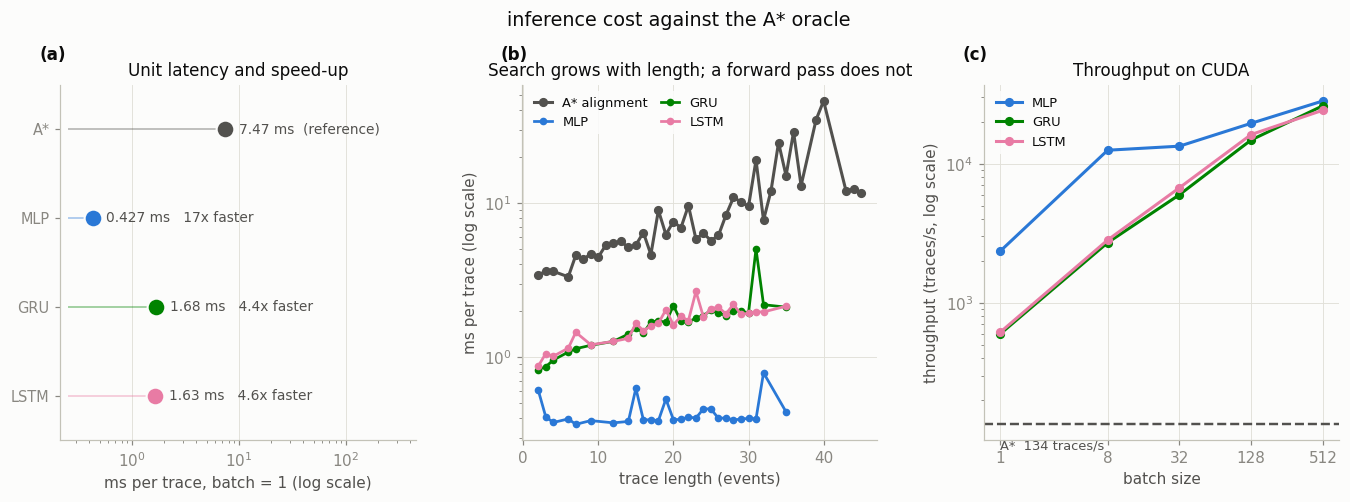

In [23]:
# Fig 9 — speed-up: unit latency, scaling with trace length, throughput
fig = plt.figure(figsize=(15, 4.2)); gs = fig.add_gridspec(1, 3, wspace=.3)

ax = fig.add_subplot(gs[0, 0])
names = ["A*"] + [LABEL[f] for f in ARCHS]
vals = [astar_ms] + [online[online.method == LABEL[f]]["ms/trace"].mean() for f in ARCHS]
cols = [ORACLE] + [MCOL[f] for f in ARCHS]
lo = min(vals)
for i, (v, c) in enumerate(zip(vals, cols)):
    ax.plot([lo * .6, v], [i, i], color=c, lw=1.3, alpha=.35, zorder=2)
    ax.scatter([v], [i], s=135, color=c, zorder=4, edgecolor=SURF, linewidth=1.4)
    ax.text(v * 1.35, i, f"{v:.3g} ms" + ("  (reference)" if i == 0
            else f"   {fmt_speedup(astar_ms/v)}"), va="center", fontsize=9, color=INK2)
ax.set_xscale("log"); ax.set_xlim(lo * .5, max(vals) * 60)
ax.set_yticks(range(len(names)), names, fontsize=9.5); ax.set_ylim(len(names)-.5, -.5)
ax.grid(axis="y", visible=False); ax.set_xlabel("ms per trace, batch = 1 (log scale)")
ax.set_title("Unit latency and speed-up")

ax = fig.add_subplot(gs[0, 1])
la = pd.concat(LAT_A.values()); g = la.groupby("length")["ms"].agg(["median", "count"])
g = g[g["count"] >= 3]
ax.plot(g.index.values, g["median"].values, marker="o", ms=5, lw=2, color=ORACLE,
        label="A* alignment", zorder=3)
cfg0 = CFGS[0]; d0 = DATA[cfg0]
for fam in ARCHS:
    xs, ys = [], []
    for L in g.index.values:
        pool = [t for t in d0["Xte"] if len(t) == L][:24]
        if len(pool) < 4: continue
        xs.append(L); ys.append(bench_latency(fam, MODELS[cfg0][fam], pool, d0["a2i"], batch=1))
    ax.plot(xs, ys, marker="o", ms=4, lw=1.8, color=MCOL[fam], label=LABEL[fam], zorder=3)
ax.set_yscale("log"); ax.set_xlabel("trace length (events)")
ax.set_ylabel("ms per trace (log scale)")
ax.set_title("Search grows with length; a forward pass does not")
legend_on_data(ax, loc="upper left", ncol=2, columnspacing=1.0, handlelength=1.4)

ax = fig.add_subplot(gs[0, 2])
for fam in ARCHS:
    sub = df_lat[(df_lat.family == fam) & (df_lat.device == DEVICE)].groupby("batch")["ms/trace"].mean()
    ax.plot(sub.index.values, 1000 / sub.values, marker="o", ms=5, lw=2,
            color=MCOL[fam], label=LABEL[fam], zorder=3)
ax.axhline(1000 / astar_ms, color=ORACLE, lw=1.6, ls="--", zorder=2)
ax.text(BATCHES[0], 1000 / astar_ms * .78, f"A*  {1000/astar_ms:.0f} traces/s",
        fontsize=8.5, color=ORACLE, va="top")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xticks(BATCHES, [str(b) for b in BATCHES])
ax.get_xaxis().set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("batch size"); ax.set_ylabel("throughput (traces/s, log scale)")
ax.set_title(f"Throughput on {DEVICE.upper()}"); legend_on_data(ax, loc="upper left")
fig.suptitle("inference cost against the A* oracle", fontsize=12.5, color=INK, y=1.04)
label_panels(fig); save_fig(fig, "fig9_speedup"); plt.show()

## 11 · Consolidated results

In [24]:
agg = (df_metrics.groupby("model")[["accuracy", "F1 vs A*", "ROC-AUC", "MAE counts",
                                     "F1 skip", "F1 insert", "F1 rework",
                                     "type accuracy", "F1 real GT"]]
       .mean().reindex([LABEL[f] for f in ARCHS]).round(3))
agg["architecture"] = [BEST[f]["name"] for f in ARCHS]
agg["params"] = [n_params(MODELS[CFGS[0]][f]) for f in ARCHS]
agg["ms/trace"] = [online[online.method == LABEL[f]]["ms/trace"].mean() for f in ARCHS]
agg["speed-up"] = (astar_ms / agg["ms/trace"]).round(1)
agg["train s"] = [np.mean([HIST[c][f]["train_s"] for c in CFGS]) for f in ARCHS]
df_final = agg.round(3)
df_final.to_csv("poisson_summary.csv")

SUMMARY = {
    "oracle": {"models": int(len(df_oracle)),
               "clean fitness": round(float(df_oracle["fitness (clean log)"].mean()), 6),
               "ground truth accuracy": round(float(df_oracle.accuracy.mean()), 4),
               "ms/trace": round(float(df_oracle["ms/trace"].median()), 2)},
    "best architectures": {LABEL[f]: BEST[f]["name"] for f in ARCHS},
    "surrogates": df_final.reset_index().to_dict("records"),
    "inference": {"A* ms/trace": round(float(astar_ms), 3),
                  "best surrogate ms/trace": round(float(agg["ms/trace"].min()), 4),
                  "max batched speed-up": round(float(
                      astar_ms / df_lat[(df_lat.family != "astar") &
                                        (df_lat.device == DEVICE)]["ms/trace"].min()), 0),
                  "device": DEVICE},
    "streaming": df_stream.to_dict("records"),
}
json.dump(SUMMARY, open("poisson_summary.json", "w", encoding="utf-8"),
          ensure_ascii=False, indent=2, default=float)
print("Exports: poisson_oracle_accuracy.csv | poisson_arch_search.csv | poisson_metrics.csv")
print("         poisson_streaming.csv | poisson_latency.csv | poisson_summary.csv/.json")
print(f"\nA* reference: {astar_ms:.2f} ms/trace | GT accuracy {df_oracle.accuracy.mean():.4f}")
df_final

Exports: poisson_oracle_accuracy.csv | poisson_arch_search.csv | poisson_metrics.csv
         poisson_streaming.csv | poisson_latency.csv | poisson_summary.csv/.json

A* reference: 7.47 ms/trace | GT accuracy 1.0000


,accuracy,F1 vs A*,ROC-AUC,MAE counts,F1 skip,F1 insert,F1 rework,type accuracy,F1 real GT,architecture,params,ms/trace,speed-up,train s
model,,,,,,,,,,,,,,
MLP,0.942,0.929,0.975,0.325,0.898,0.600,0.460,0.650,0.873,MLP 512-256-128,192259,0.427,17.5,10.621
GRU,0.969,0.961,0.992,0.154,0.935,0.868,0.835,0.894,0.848,GRU L2 h128,181123,1.678,4.4,18.460
LSTM,0.967,0.959,0.989,0.141,0.946,0.876,0.857,0.912,0.866,LSTM L2 h128,238979,1.632,4.6,19.198


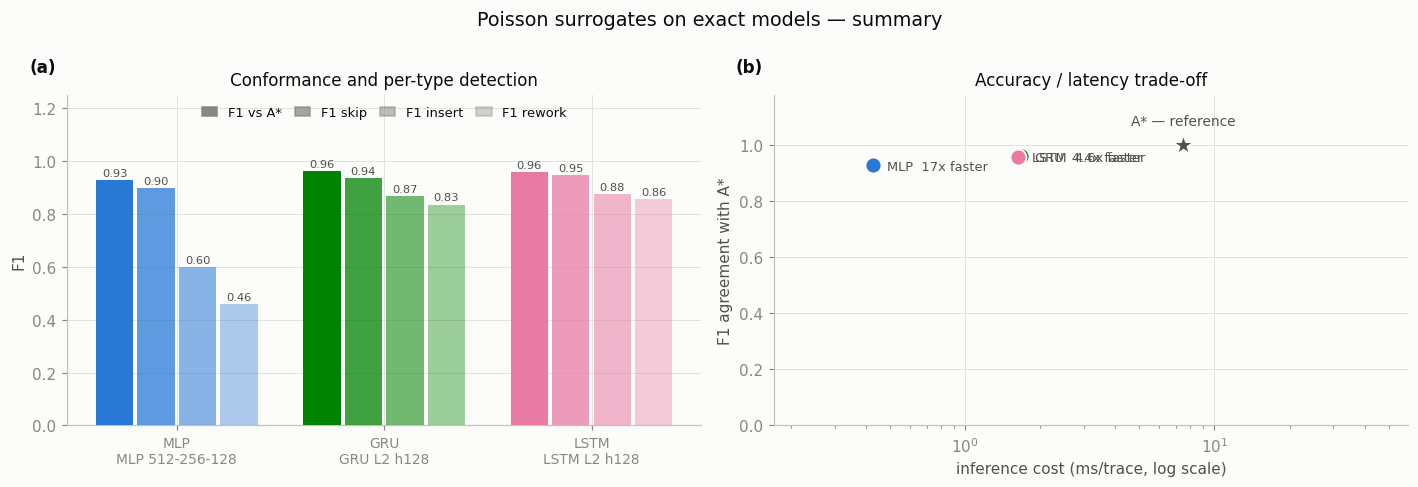

In [25]:
# Fig 10 — the summary figure
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
x = np.arange(len(ARCHS)); w = .2
series = [("F1 vs A*", 1.0), ("F1 skip", .75), ("F1 insert", .55), ("F1 rework", .38)]
for j, (col, al) in enumerate(series):
    vals = [df_final.loc[LABEL[f], col] for f in ARCHS]
    b = ax.bar(x + (j - 1.5) * w, vals, w * .9,
               color=[MCOL[f] for f in ARCHS], alpha=al, zorder=3)
    for bb, v in zip(b, vals):
        ax.text(bb.get_x() + bb.get_width()/2, v + .015, f"{v:.2f}", ha="center",
                fontsize=7.5, color=INK2)
ax.set_xticks(x, [f"{LABEL[f]}\n{BEST[f]['name']}" for f in ARCHS], fontsize=9)
ax.set_ylim(0, 1.25); ax.set_ylabel("F1")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=MUTED, alpha=a) for _, a in series],
          labels=[c for c, _ in series], fontsize=8.5, loc="upper center", ncol=4,
          columnspacing=1.0, handlelength=1.2)
ax.set_title("Conformance and per-type detection")

ax = axes[1]
ax.scatter([astar_ms], [1.0], s=210, marker="*", color=ORACLE, zorder=5,
           edgecolor=SURF, linewidth=1.2)
ax.annotate("A* — reference", (astar_ms, 1.0), textcoords="offset points",
            xytext=(0, 13), ha="center", fontsize=9, color=INK2)
for f in ARCHS:
    ms = df_final.loc[LABEL[f], "ms/trace"]; f1 = df_final.loc[LABEL[f], "F1 vs A*"]
    ax.scatter([ms], [f1], s=110, color=MCOL[f], zorder=4, edgecolor=SURF, linewidth=1.2)
    ax.annotate(f"{LABEL[f]}  {fmt_speedup(astar_ms/ms)}", (ms, f1),
                textcoords="offset points", xytext=(9, -3), fontsize=8.5, color=INK2)
ax.set_xscale("log"); ax.set_xlim(df_final["ms/trace"].min() * .4, astar_ms * 8)
ax.set_ylim(0, 1.18); ax.set_xlabel("inference cost (ms/trace, log scale)")
ax.set_ylabel("F1 agreement with A*")
ax.set_title("Accuracy / latency trade-off")
fig.suptitle("Poisson surrogates on exact models — summary", fontsize=12.5, color=INK, y=1.02)
plt.tight_layout(); label_panels(fig); save_fig(fig, "fig10_summary"); plt.show()

## 12 · Reading the results

## 13 · Reproducibility footprint

In [26]:
def _ver(m):
    try: return __import__(m).__version__
    except Exception: return "n/a"
manifest = {
    "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"), "seed": SEED, "device": DEVICE,
    "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
    "smoke": os.environ.get("SMOKE") == "1", "python": platform.python_version(),
    "versions": {m: _ver(m) for m in ["pm4py", "torch", "numpy", "pandas", "sklearn",
                                      "lxml", "matplotlib"]},
    "spec": "Démonstration_Mathématique (1).pdf — Def. 7.1, Th. 4.1, Th. 6.2, eq. 14/16/18",
    "dataset": {"name": "PDC 2021", "train/eval": CFGS, "oracle sweep": GT_CFGS,
                "search": SEARCH_CFGS, "stream": STREAM_CFGS},
    "config": {"N_CLEAN": N_CLEAN, "PASSES": PASSES, "MAXLEN": MAXLEN, "PI": PI,
               "ALPHA": ALPHA, "TAU_DOC": TAU_DOC, "FIT_TOL": FIT_TOL,
               "EPOCHS": EPOCHS, "SEARCH_EPOCHS": SEARCH_EPOCHS,
               "BATCHES": BATCHES, "STREAM_N": STREAM_N, "WARMUP": WARMUP,
               "PREQ_W": PREQ_W},
    "selected architectures": {LABEL[f]: BEST[f] for f in ARCHS},
}
json.dump(manifest, open("poisson_run_manifest.json", "w", encoding="utf-8"),
          ensure_ascii=False, indent=2, default=str)
print(json.dumps(manifest, ensure_ascii=False, indent=2, default=str))

{
  "timestamp": "2026-08-21 08:25:31",
  "seed": 42,
  "device": "cuda",
  "gpu": "NVIDIA GeForce RTX 3070 Ti Laptop GPU",
  "smoke": false,
  "python": "3.11.9",
  "versions": {
    "pm4py": "2.7.22.2",
    "torch": "2.5.1+cu121",
    "numpy": "1.26.4",
    "pandas": "2.3.3",
    "sklearn": "1.6.1",
    "lxml": "6.0.2",
    "matplotlib": "3.8.2"
  },
  "spec": "Démonstration_Mathématique (1).pdf — Def. 7.1, Th. 4.1, Th. 6.2, eq. 14/16/18",
  "dataset": {
    "name": "PDC 2021",
    "train/eval": [
      "000000",
      "100000",
      "011010",
      "121111"
    ],
    "oracle sweep": [
      "000000",
      "100000",
      "010000",
      "020000",
      "001000",
      "000100",
      "000010",
      "000001",
      "011010",
      "101010",
      "110101",
      "121111"
    ],
    "search": [
      "000000",
      "121111"
    ],
    "stream": [
      "000000",
      "121111"
    ]
  },
  "config": {
    "N_CLEAN": 1000,
    "PASSES": 6,
    "MAXLEN": 45,
    "PI": {
      "none